# 06C — Combine → NFL transfer: robustness and scouting insights

**Status: AUTHORED 2026-10-13 — AWAITING USER EXECUTION.** Nothing here has been run by its author. This notebook does **not** assume that the primary experiment of 06B succeeded: every section reports what it finds, including nothing.

**Question.** When and for whom does any predictive gain exist — and is the evidence strong enough to carry a dimension into a scouting score?

| Section | Question | Status of the answer |
|---|---|---|
| Position groups | does the gain differ by position, beyond estimation noise? | secondary (H4) |
| Draft cohorts | does it hold when a whole cohort — encoders included — is left out? | secondary (H5) |
| Exposure, context | does it keep its direction under every declared exposure and context rule? | secondary (H5); no rule is selected |
| Matched prospects | among athletes with near-identical stopwatch and body, do models order their NFL movement? | secondary (H6), mandatory |
| Physical mechanism | does Combine speed development relate to NFL acceleration after official times? | descriptive |
| TCN added value | seed replicates, re-ranking, and — only after a gain — which part of the curve the read-out uses | secondary / descriptive |
| Null controls | do permuted labels or permuted athlete linkage remove the gain? | check of the pipeline |
| Scoring readiness | which dimension is `descriptive_ready`, `exploratory`, `predictive_candidate`, `predictive_validated`, … | rule-based, conservative |

No athlete score is built here. Subgroup, exposure and matched-pair results are exploratory unless the pooled primary comparison is established; a case study is an illustration, never evidence.

**Prerequisite.** 06A and 06B passed their gates in the same `RUN_MODE`. PyTorch is required (leave-one-cohort-out and seed-replicate encoders).

In [3]:
# ---------------------------------------------------------------- Configuration
RUN_MODE = 'full'       # 'smoke' | 'full' — must match notebooks 06A and 06B
FORCE_REBUILD = False
SAVE_FIGURES = True
SAVE_TABLES = True
SAVE_MODELS = True       # leave-one-cohort-out and seed-replicate encoders → artifacts/models/advanced_movement/transfer/tcn
SEED = 20261011
DEVICE = 'auto'
BATCH_SIZE = 32
MAX_EPOCHS = None        # None = the training budget stored in the notebook-03 checkpoints

RUN_LOCO = True          # leave-one-draft-cohort-out: refits FPCA and TCN-B without each cohort (one encoder per cohort)
RUN_SEEDS = True         # TCN-B training-seed replicates (reuses the 04B checkpoints where the 06A audit cleared them)
RUN_PERMUTATIONS = True  # outcome and linkage permutation checks (n_perm refits of two ridge models; no encoder is refitted)
RUN_ATTRIBUTION = 'if_gain'   # 'if_gain' = occlusion read-out only when M5 vs M1 is established · 'always' · 'never'

## 0. Setup and hand-over from notebooks 06A and 06B

In [4]:
from nflbdb.data.config import Phase01Config, configure_runtime

cfg = Phase01Config.load()
configure_runtime(cfg)

from dataclasses import replace
from pathlib import Path

import numpy as np
import polars as pl
from IPython.display import Markdown, display

from nflbdb.data.utils import utc_now
from nflbdb.research.advanced_movement import atlas as at
from nflbdb.research.advanced_movement import checkpoint as ck
from nflbdb.research.advanced_movement import config as amc
from nflbdb.research.advanced_movement import data as amd
from nflbdb.research.advanced_movement import fpca as fp
from nflbdb.research.advanced_movement import fpca_eval as fe
from nflbdb.research.advanced_movement import nfl_outcomes as no
from nflbdb.research.advanced_movement import robust as rb
from nflbdb.research.advanced_movement import robust_train as rt
from nflbdb.research.advanced_movement import sequences as seq
from nflbdb.research.advanced_movement import tcn
from nflbdb.research.advanced_movement import transfer as tr
from nflbdb.research.advanced_movement import transfer_figures as tf
from nflbdb.research.advanced_movement import transfer_models as tm
from nflbdb.research.advanced_movement import transfer_repr as trp
from nflbdb.research.advanced_movement import transfer_robust as tx
from nflbdb.research.advanced_movement import transfer_validation as tv
from nflbdb.research.advanced_movement.artifacts import TransferStore
from nflbdb.research.contracts import conform

controls = amc.NotebookControls(run_mode=RUN_MODE, force_rebuild=FORCE_REBUILD, save_figures=SAVE_FIGURES, save_tables=SAVE_TABLES,
                                save_models=SAVE_MODELS, device=DEVICE, seed=SEED, batch_size=BATCH_SIZE, max_epochs=MAX_EPOCHS or 200).validate()
acfg = amc.AdvancedConfig().for_mode(controls)
fcfg = fp.FpcaConfig().for_mode(controls)
tc = tr.TransferConfig().for_mode(controls)
store = TransferStore(cfg, controls)
up = store.upstream
device = amc.resolve_device(controls.device)
amc.seed_everything(controls.seed)

NB = {'00': '00_research_setup_and_data_audit.ipynb', '01': '01_sequence_eda_and_alignment.ipynb', '02': '02_functional_pca_baseline.ipynb',
      '03': '03_self_supervised_tcn.ipynb', '04A': '04a_feature_characteristic_atlas.ipynb', '04B': '04b_tcn_robustness_and_shortlist.ipynb',
      '05A': '05a_nfl_movement_outcome_eda.ipynb', '06A': '06a_transfer_cohort_and_leakage_audit.ipynb',
      '06B': '06b_combine_to_nfl_transfer_benchmark.ipynb'}
PROV = {'notebook': '06c_transfer_robustness_and_scouting_insights.ipynb', 'run_mode': controls.run_mode, 'seed': controls.seed}
nm = lambda c, suffix: replace(c, name=f'{c.name}_{suffix}')            # a contract under a stage-specific table name

def save(df, contract):
    return store.write(df, contract, '06C', PROV) if controls.save_tables else conform(df, contract)

# ---- hand-over, verified: frozen targets ↔ 06A audit ↔ 06B benchmark
registry_doc, freeze_audit = tr.audit_freeze(store.nfl, controls.run_mode)
tr.assert_frozen(freeze_audit)
targets, ocfg = tr.frozen_targets(registry_doc)
primary = tr.primary_target(targets)
folds = store.require(tr.FOLDS, NB['06A'])
audit = tr.require_audit(store, registry_doc, folds)
bench = store.read_json('transfer_benchmark_manifest', NB['06B'])
if bench.get('gate_06b') != 'PASS' or bench.get('targets_version_hash') != registry_doc['version_hash'] or bench.get('folds_hash') != audit['folds_hash']:
    raise tr.TransferGateError('notebook 06B did not pass its gate with the current frozen targets and folds: rerun 06B first')
contract = store.read_json(tr.INPUT_CONTRACT, NB['06A'])
families, design_columns = contract['families'], contract['design_columns']
PRIMARY_INPUT, FPCA_K = contract['primary_input'], int(contract['fpca_k'])
FOLDS_HASH, TARGETS_HASH = audit['folds_hash'], registry_doc['version_hash']
P, U = primary.target_id, primary.unit

label = 'SMOKE — wiring check, numbers are not results' if controls.smoke else 'FULL'
display(Markdown(f'**Run mode: `{controls.run_mode}`** ({label}) · device `{device}` · gates 06A `{audit["gate_06a"]}`, 06B `{bench["gate_06b"]}` · '
                 f'primary target `{P}` · paired cohort {bench["n_paired_cohort"]} athletes'))

**Run mode: `full`** (FULL) · device `cpu` · gates 06A `PASS`, 06B `PASS` · primary target `O2.accel_sust05_mean` · paired cohort 284 athletes

In [5]:
# ---- data and the saved products of 06B (nothing is refitted in this cell)
manifest = up.require(amd.MANIFEST, NB['00'])
athletes = up.require(amd.ATHLETES, NB['00'])
splits = up.require(amd.SPLITS, NB['00'])
seq_frames = up.require(seq.SEQ_FRAMES, NB['01'])
windows = up.require(ck.WINDOWS, NB['02'])
attempt_values = store.atlas.require(at.ATTEMPT_VALUES, NB['04A'])
shortlist = store.atlas.require(rb.SHORTLIST, NB['04B'])
plays = store.nfl.require(no.plays_contract(ocfg), NB['05A'])
mart = amd.AdvInputs(cfg, acfg).mart().filter(pl.col('nfl_id').is_in(athletes['nfl_id'].to_list()))
official = at.official_table(mart, athletes)
compat = store.require(tr.COMPAT, NB['06A'])
support = store.require(tm.SUPPORT, NB['06B'])
attempts = store.require(trp.named(trp.ATTEMPT_REP, 'outer'), NB['06B'])
enc_fits = store.require(trp.named(trp.ENC_FITS, 'outer'), NB['06B'])
oof_all, labels_all, prep = (store.require(c, NB['06B']) for c in (tm.OOF, tm.OOF_TARGETS, tm.PREP))
perf_all, paired_all = store.require(tm.PERF, NB['06B']), store.require(tm.PAIRED, NB['06B'])

main = lambda df: df.filter((pl.col('analysis') == tm.PRIMARY) & (pl.col('cohort') == tm.PRIMARY))
oof, labels, perf, paired = main(oof_all), main(labels_all), main(perf_all), main(paired_all)

ss = seq.SequenceSet.from_frames(seq_frames, manifest)
curves = fp.build_curves(ss, acfg, fp.SPEC[PRIMARY_INPUT])
tset = tr.TargetSet(plays, ocfg, targets)
enc_splits = tr.encoder_splits(folds, splits)
ORDER = dict(windows.select('seq_id', 'attempt_order').iter_rows())
blocks = tm.RepBlocks(attempts, ORDER, scheme='outer', how=tc.aggregation)
d = tm.Design.build(folds, official, design_columns).keep_ids(support.filter(pl.col('in_paired_cohort'))['nfl_id'].to_list())
dP = d.keep_ids(oof.filter(pl.col('target_id') == P)['nfl_id'].unique().to_list())      # athletes of the primary-target comparison
FOLD_IDS = sorted(np.unique(d.fold).tolist())

LADDER = {m.model: m for m in tm.model_ladder(tc) if m.model in set(bench['models'])}
PAIRS = tm.comparisons(tc)
CORE = [m for m in ('M1', 'M2', 'M3', 'M4', 'M5', 'M6') if m in LADDER]            # models carried through the robustness analyses
CORE_MODELS = [LADDER[m] for m in ('MEAN', 'M0', *CORE) if m in LADDER]
REP_MODELS = [m for m in CORE if m != 'M1']
N = dP.n
NTXT, SRC = f'{N} athletes of the paired cohort', 'transfer_oof_predictions (notebook 06B)'

tcfg_exec = rt.executed_config(up.models_dir, families['TCN']) or rt.reconstructed_config(up.require(tcn.DESIGN, NB['03']), controls, fcfg)
tcfg = tcfg_exec if MAX_EPOCHS is None else replace(tcfg_exec, max_epochs=int(MAX_EPOCHS))
scalars = {'ENG': trp.scalar_matrix(attempt_values, families['ENG'], curves.seq_ids),
           'SPEED2': trp.scalar_matrix(attempt_values, families['SPEED2'], curves.seq_ids)}
REP_FILES = [up.parquet(seq.SEQ_FRAMES), up.parquet(amd.SPLITS), store.parquet(tr.FOLDS), store.atlas.parquet(at.ATTEMPT_VALUES)]
REP_PARAMS = {'folds_hash': FOLDS_HASH, 'config': acfg.params(), 'input': PRIMARY_INPUT, 'seed': controls.seed,
              'features': {'ENG': families['ENG'], 'SPEED2': families['SPEED2']}}
BASE_PARAMS = {'folds_hash': FOLDS_HASH, 'targets_hash': TARGETS_HASH, 'transfer_config': tc.params(), 'design_columns': design_columns,
               'paired_cohort': int(d.n), 'models': [m.model for m in CORE_MODELS]}
OOF_C = [tm.OOF, tm.OOF_TARGETS, tm.PREP]

display(Markdown(f'**Primary comparison carried over from 06B** — `{P}`, {N} athletes'))
with pl.Config(tbl_rows=30, float_precision=4):
    display(paired.filter((pl.col('target_id') == P) & (pl.col('metric') == 'delta_rmse'))
            .select('model', 'reference', pl.col('estimate').alias('delta_rmse'), 'ci_lower', 'ci_upper', 'relative', 'established', 'worse').sort('reference', 'model'))

**Primary comparison carried over from 06B** — `O2.accel_sust05_mean`, 284 athletes

model,reference,delta_rmse,ci_lower,ci_upper,relative,established,worse
str,str,f64,f64,f64,f64,bool,bool
"""M1""","""M0""",0.0003,-0.0021,0.0026,0.0014,false,false
"""M2""","""M1""",0.0001,-0.0002,0.0004,0.0005,false,false
"""M3""","""M1""",-0.0003,-0.0009,0.0002,-0.0017,false,false
"""M4""","""M1""",-0.0003,-0.0009,0.0001,-0.0019,false,false
"""M5""","""M1""",0.0003,-0.0008,0.0015,0.0016,false,false
"""M5S""","""M1""",-0.0004,-0.0015,0.0006,-0.0024,false,false
"""M6""","""M1""",0.0001,-0.0012,0.0013,0.0003,false,false
"""M7_PC2""","""M1""",-0.0001,-0.0006,0.0004,-0.0004,false,false
"""M7_PC4""","""M1""",0.0001,-0.0012,0.0015,0.0007,false,false


## 1. Synthetic validation

Three checks with a known answer: matched-pair formation (same position, inside the caliper, formed without any NFL value, athlete-cluster intervals), grouped permutation tests (a planted gain lies outside both null distributions; a study without a trait lies inside), and outcome-label leakage (a block that contains the label is exposed; the representation module cannot read a label; `predictive_validated` needs every robustness check). **Every row must read `PASS`.**

In [6]:
validation_report = tv.run_all(tv.CHECKS_06C)
with pl.Config(tbl_rows=30, fmt_str_lengths=240):
    display(validation_report)
tv.assert_all_passed(validation_report)

check,status,detail
str,str,str
"""matched_pair_formation""","""PASS""","""379 unordered same-position pairs inside the caliper; a model that knows the outcome orders 97 % of them, a random one about half; intervals resample athletes because pairs reuse them"""
"""grouped_permutation""","""PASS""","""labels and representation rows are permuted between ATHLETES inside a position group; the planted gain lies outside both null distributions and a study without a trait lies inside"""
"""outcome_label_leakage""","""PASS""","""a block that contains the label is obvious (R² ≈ 1) and unlike any permutation; clean blocks show no gain without a trait; labels are requested with training athletes only; the representation module cannot read an NFL label; readiness is 'v…"


## 2. Position-level analysis

The pooled models of 06B (additive, unpenalised position effects) are **scored inside each position group**; no position-specific network or model is fitted, because TE and other small groups could not support one. Two things are separated:

- *apparent variation* — the point estimates differ between positions, as they always will;
- *estimation uncertainty* — per-position intervals, and a permutation test of whether the squared-error gain differs between positions more than a random relabelling of athletes produces.

A group below the declared minimum size is shown with its estimate and **no** interval. A gain that exists in one position only is case D of the decision tree: investigate, require replication, make no universal claim.

11:47:22 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:06C] transfer_subgroup_performance: 2,016 rows → warehouse/gold/advanced_movement/transfer/transfer_subgroup_performance.parquet
11:47:22 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:06C] transfer_subgroup_comparisons: 1,728 rows → warehouse/gold/advanced_movement/transfer/transfer_subgroup_comparisons.parquet
11:47:22 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:06C] transfer_gain_heterogeneity: 30 rows → warehouse/gold/advanced_movement/transfer/transfer_gain_heterogeneity.parquet


**Δ RMSE against M1 by position group** — `O2.accel_sust05_mean` (pooled fit, subgroup scoring; unit: athlete)

group,model,n_athletes,delta_rmse,ci_lower,ci_upper,established,worse
str,str,i64,f64,f64,f64,bool,bool
"""DB""","""M2""",67,-0.0002,-0.0005,0.0002,false,false
"""DL""","""M2""",70,0.0004,-0.0005,0.0015,false,false
"""OL""","""M2""",63,0.0001,-0.0007,0.0008,false,false
"""TE""","""M2""",20,-0.0001,-0.0008,0.0005,false,false
"""WR""","""M2""",64,0.0001,-0.0003,0.0004,false,false
"""DB""","""M3""",67,-0.0002,-0.0010,0.0008,false,false
"""DL""","""M3""",70,-0.0005,-0.0017,0.0008,false,false
"""OL""","""M3""",63,-0.0002,-0.0008,0.0004,false,false
"""TE""","""M3""",20,0.0010,-0.0013,0.0028,false,false


**Is the gain different between position groups?** (permutation of the group labels; small p = it differs)

model,reference,n_groups,n_athletes,statistic,p_value,n_perm
str,str,i64,i64,f64,f64,i64
"""M2""","""M1""",5,284,0.0000,0.7512,200
"""M3""","""M1""",5,284,0.0000,0.3433,200
"""M4""","""M1""",5,284,0.0000,0.5672,200
"""M5""","""M1""",5,284,0.0000,0.4129,200
"""M6""","""M1""",5,284,0.0000,0.9552,200


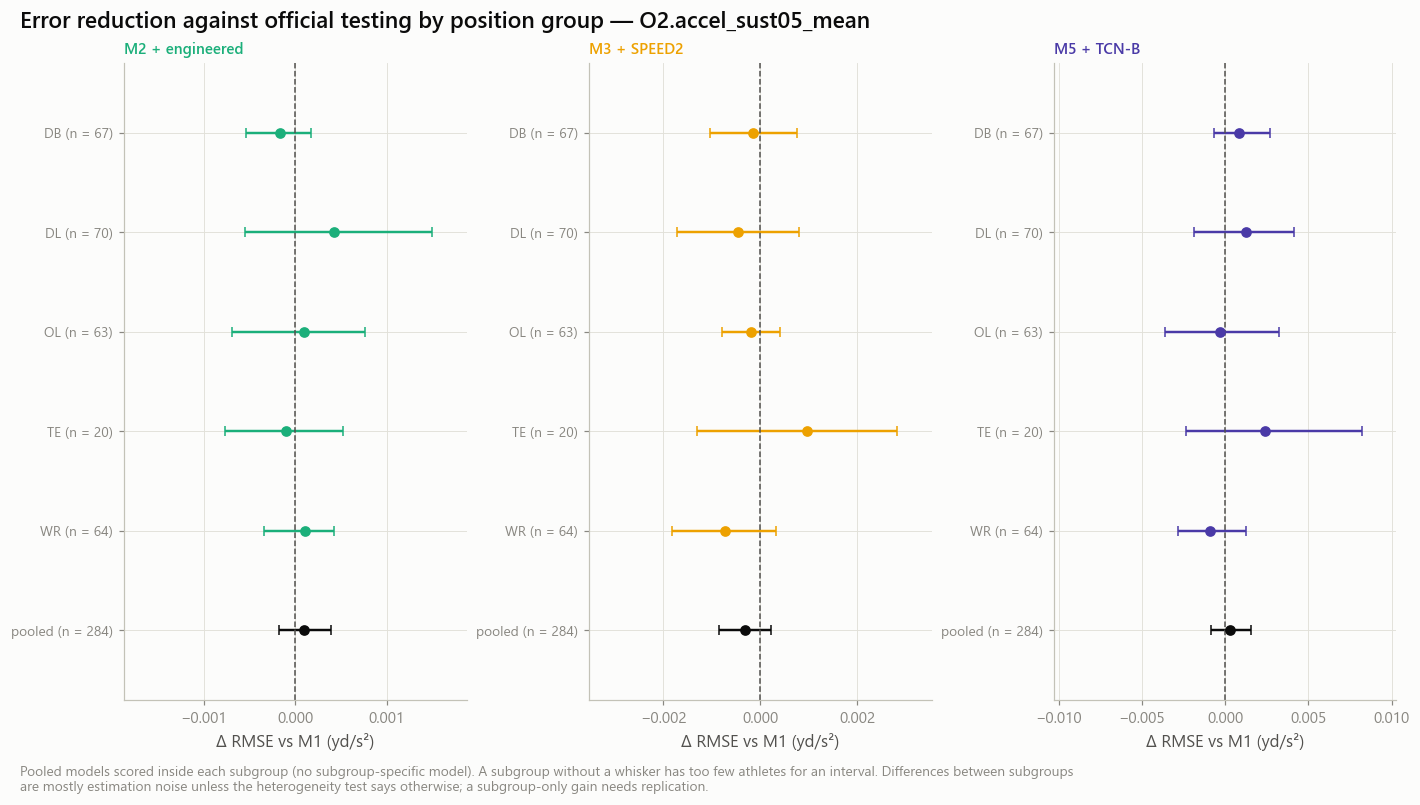

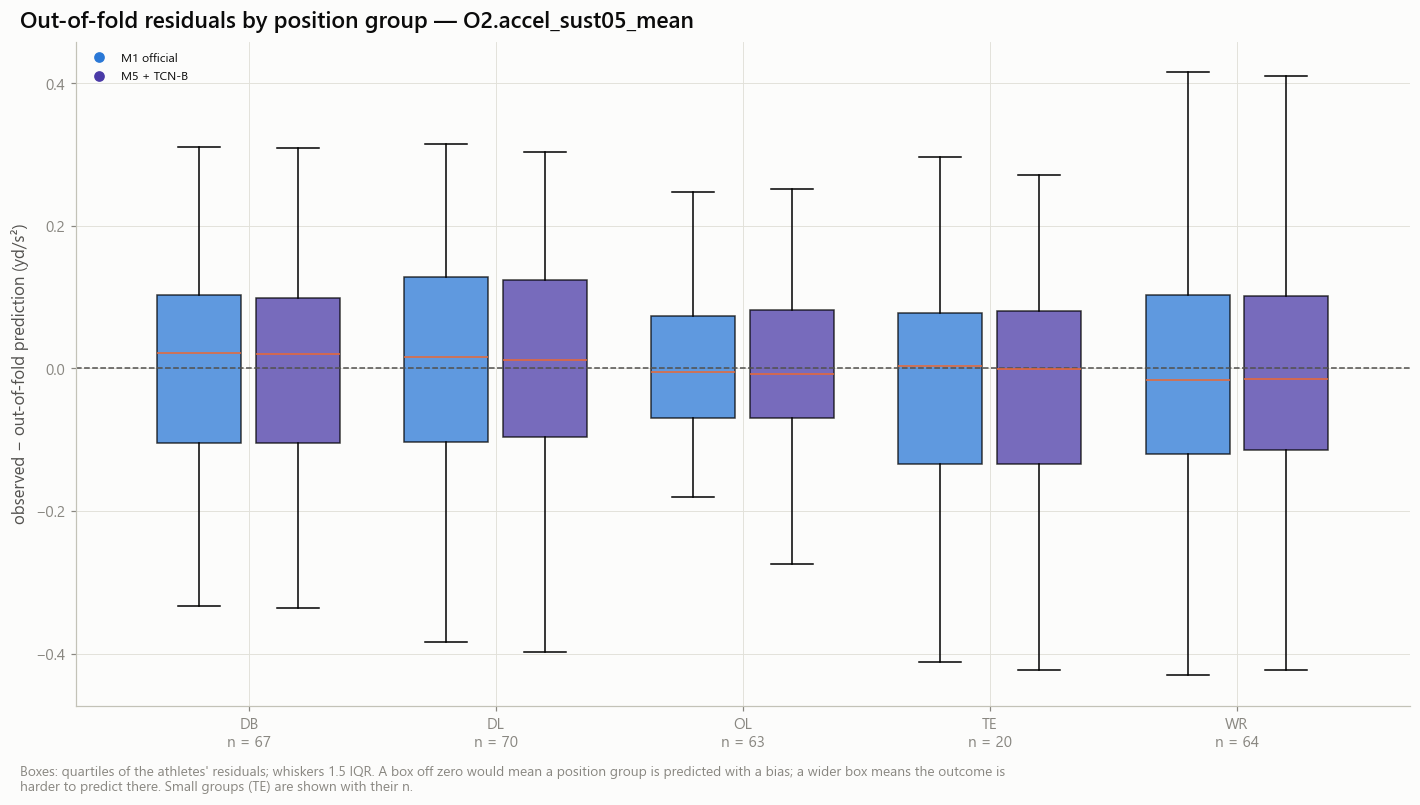

In [7]:
sub = {by: tx.subgroup_tables(oof, by, PAIRS, tc, controls.seed) for by in ('position_group', 'draft_year')}
sub_perf = save(pl.concat([s[tx.SUB_PERF.name] for s in sub.values()]), tx.SUB_PERF)
sub_paired = save(pl.concat([s[tx.SUB_PAIRED.name] for s in sub.values()]), tx.SUB_PAIRED)
hetero = save(pl.concat([tx.heterogeneity(oof, by, [(m, tm.REFERENCE) for m in REP_MODELS], tc, controls.seed) for by in ('position_group', 'draft_year')]),
              tx.HETERO)

pos_view = sub_paired.filter((pl.col('target_id') == P) & (pl.col('group_type') == 'position_group') & (pl.col('reference') == tm.REFERENCE)
                             & (pl.col('metric') == 'delta_rmse') & pl.col('model').is_in(REP_MODELS))
display(Markdown(f'**Δ RMSE against M1 by position group** — `{P}` (pooled fit, subgroup scoring; unit: athlete)'))
with pl.Config(tbl_rows=60, float_precision=4):
    display(pos_view.select('group', 'model', 'n_athletes', pl.col('estimate').alias('delta_rmse'), 'ci_lower', 'ci_upper', 'established', 'worse')
            .sort('model', 'group'))
    display(Markdown('**Is the gain different between position groups?** (permutation of the group labels; small p = it differs)'))
    display(hetero.filter((pl.col('target_id') == P) & (pl.col('group_type') == 'position_group')).select('model', 'reference', 'n_groups', 'n_athletes', 'statistic', 'p_value', 'n_perm'))
store.show(tf.plot_subgroup_gains(sub_paired, paired, P, 'position_group', [m for m in ('M2', 'M3', 'M5') if m in LADDER], U,
                                  f'Error reduction against official testing by position group — {P}'),
           'AM06C_01_position_specific_model_gains', {'subgroups': pos_view}, publication=True, source=SRC, n=NTXT)
store.show(tf.plot_residuals_by_position(oof, P, [m for m in ('M1', 'M5') if m in LADDER], U), 'AM06C_08_nfl_outcome_residuals_by_position',
           {'oof': oof.filter((pl.col('target_id') == P) & pl.col('model').is_in(['M1', 'M5']))}, source=SRC, n=NTXT)

## 3. Draft-cohort generalisation

Two views, both reported:

1. **Error by cohort under the stratified folds** — the 06B predictions scored inside each draft cohort.
2. **Leave-one-draft-cohort-out** — every athlete is predicted by models that never saw his cohort: prediction models, preprocessing **and representation encoders** (FPCA and TCN-B are refitted on the other cohorts; the cohort dummy of an unseen cohort is zero).

A cohort difference is **not** an athlete-development effect: the 2025 Combine has about a quarter of the positional noise of 2023 / 2024, and older cohorts have a longer NFL follow-up. The second view asks only whether a conclusion survives a change of sensor generation and exposure.

**Held-out RMSE by draft cohort, stratified folds** — `O2.accel_sust05_mean`

model,2023,2024,2025
str,f64,f64,f64
"""M1""",0.2276,0.1398,0.1516
"""M2""",0.2272,0.1403,0.1513
"""M3""",0.2278,0.1402,0.1520
"""M4""",0.2277,0.1413,0.1509
"""M5""",0.2274,0.1395,0.1512
"""M6""",0.2277,0.1397,0.1515


group,model,n_athletes,delta_rmse,ci_lower,ci_upper
str,str,i64,f64,f64,f64
"""2023""","""M2""",103,0.0004,-0.0001,0.0008
"""2024""","""M2""",103,-0.0005,-0.0010,0.0000
"""2025""","""M2""",78,0.0003,-0.0001,0.0008
"""2023""","""M3""",103,-0.0002,-0.0012,0.0007
"""2024""","""M3""",103,-0.0004,-0.0013,0.0005
"""2025""","""M3""",78,-0.0004,-0.0011,0.0003
"""2023""","""M4""",103,-0.0001,-0.0007,0.0004
"""2024""","""M4""",103,-0.0015,-0.0029,-0.0003
"""2025""","""M4""",78,0.0007,0.0001,0.0013


11:47:31 | INFO    | nflbdb.research.advanced_movement.artifacts | [advanced_movement:REP_LOCO] computing (never run)
C:\Users\myben\Downloads\nfl-big-data-bowl-2027\nfl-big-data-bowl-2027\src\nflbdb\research\advanced_movement\tcn.py:484: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\autograd\generated\python_variable_methods.cpp:821.)
  tot += (float(rec), float(cons), 1.0)
11:49:14 | INFO    | nflbdb.research.advanced_movement.transfer_repr | [advanced_movement:TRANSFER] TCN loco fold 0: trained, 89 epochs (best 64), 97.2 s
11:51:02 | INFO    | nflbdb.research.advanced_movement.transfer_repr | [advanced_movement:TRANSFER] TCN loco fold 1: trained, 105 epochs (best 80), 107.8 s
11:52:47 | INFO    | nflbdb.research.advanced_movement.transfer_repr | [advanced_movement:TRANSFER] TCN loco fold 2: trained, 103 epochs (best

**Leave-one-cohort-out:** folds = draft cohorts {0: '2023', 1: '2024', 2: '2025'}; 284 of 284 paired-cohort athletes are represented by every cohort-held-out encoder

...

11:52:47 | INFO    | nflbdb.research.advanced_movement.artifacts | [advanced_movement:OOF_LOCO] computing (never run)
11:52:57 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:OOF_LOCO] transfer_oof_predictions_loco: 6,816 rows → warehouse/gold/advanced_movement/transfer/transfer_oof_predictions_loco.parquet
11:52:57 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:OOF_LOCO] transfer_oof_targets_loco: 852 rows → warehouse/gold/advanced_movement/transfer/transfer_oof_targets_loco.parquet
11:52:57 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:OOF_LOCO] transfer_fold_preprocessing_loco: 1,143 rows → warehouse/gold/advanced_movement/transfer/transfer_fold_preprocessing_loco.parquet
11:53:15 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:06C] transfer_model_performance_loco: 168 rows → warehouse/gold/advanced_movement/transfer/transfer_model_performance_loco.parquet
11:53:15 | INFO    | nflbdb.research.spri

**Leave-one-draft-cohort-out, Δ RMSE against M1** — `O2.accel_sust05_mean` (every athlete predicted without his cohort)

model,n_athletes,delta_rmse,ci_lower,ci_upper,relative,established,worse
str,i64,f64,f64,f64,f64,bool,bool
"""M2""",284,-0.0001,-0.0004,0.0001,-0.0006,false,false
"""M3""",284,0.0001,-0.0001,0.0004,0.0006,false,false
"""M4""",284,-0.0022,-0.0038,-0.0007,-0.0111,false,true
"""M5""",284,0.0001,-0.0005,0.0006,0.0004,false,false
"""M6""",284,0.0009,-0.0002,0.0019,0.0047,false,false


… and scored inside each held-out cohort

group,model,n_athletes,delta_rmse,ci_lower,ci_upper
str,str,i64,f64,f64,f64
"""2023""","""M2""",103,0.0001,0.0000,0.0002
"""2024""","""M2""",103,-0.0010,-0.0017,-0.0001
"""2025""","""M2""",78,0.0004,0.0001,0.0007
"""2023""","""M3""",103,0.0002,0.0000,0.0005
"""2024""","""M3""",103,0.0002,-0.0004,0.0008
…,…,…,…,…,…
"""2024""","""M5""",103,-0.0004,-0.0016,0.0008
"""2025""","""M5""",78,-0.0000,-0.0014,0.0015
"""2023""","""M6""",103,0.0035,0.0021,0.0048


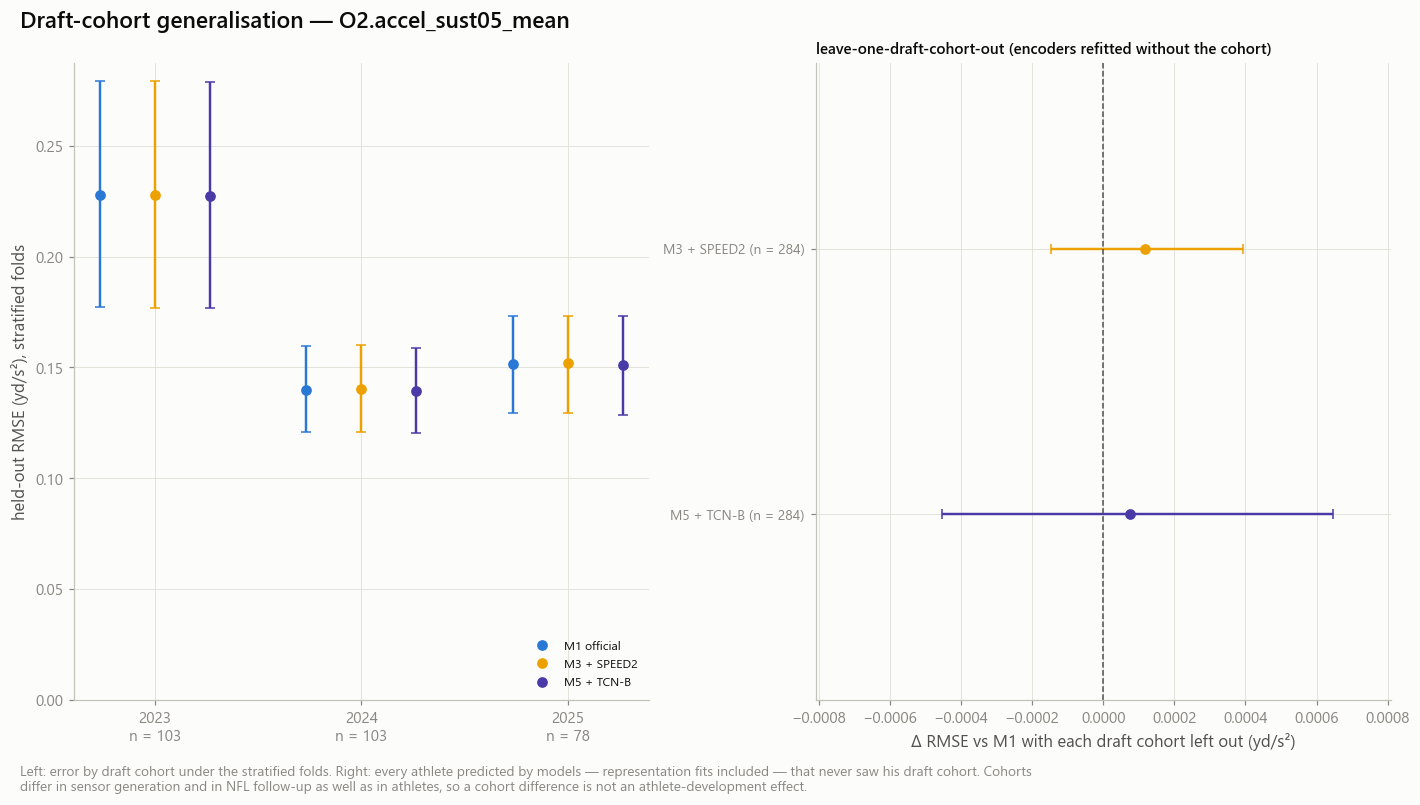

In [8]:
coh_view = sub_perf.filter((pl.col('target_id') == P) & (pl.col('group_type') == 'draft_year') & (pl.col('metric') == 'rmse') & pl.col('model').is_in(CORE))
display(Markdown(f'**Held-out RMSE by draft cohort, stratified folds** — `{P}`'))
with pl.Config(tbl_rows=60, float_precision=4):
    display(coh_view.pivot(on='group', index='model', values='estimate').sort('model'))
    display(sub_paired.filter((pl.col('target_id') == P) & (pl.col('group_type') == 'draft_year') & (pl.col('reference') == tm.REFERENCE)
                              & (pl.col('metric') == 'delta_rmse') & pl.col('model').is_in(REP_MODELS))
            .select('group', 'model', 'n_athletes', pl.col('estimate').alias('delta_rmse'), 'ci_lower', 'ci_upper').sort('model', 'group'))

LOCO_C = [nm(c, 'loco') for c in OOF_C]
loco_oof, loco_paired, loco_perf = tm.OOF.empty(), tm.PAIRED.empty(), tm.PERF.empty()
if RUN_LOCO:
    loco_splits, fold_cohort = rb.cohort_splits(splits, 0)
    loco_folds = sorted(fold_cohort)
    plan_loco = trp.RepPlan(tcfg, fcfg, FPCA_K, controls.seed, families=('ENG', 'SPEED2', 'FPCA', 'TCN', 'RAND'), compact_dims=())
    rep_loco = trp.build_representations(store, 'REP_LOCO', 'loco', curves, loco_splits, loco_folds, plan_loco, scalars, device, None, 'loco',
                                         {**REP_PARAMS, 'cohorts': {str(k): v for k, v in fold_cohort.items()}}, REP_FILES)
    blocks_loco = tm.RepBlocks(rep_loco[trp.ATTEMPT_REP.name], ORDER, scheme='loco', how=tc.aggregation)
    d_loco = tx.loco_design(d, fold_cohort)
    fams = sorted({f for m in CORE_MODELS for f in m.families})
    keep = tm.common_support(d_loco, blocks_loco, fams)
    d_loco = d_loco.keep_ids(keep.filter(pl.col('in_paired_cohort'))['nfl_id'].to_list())
    display(Markdown(f'**Leave-one-cohort-out:** folds = draft cohorts {fold_cohort}; {d_loco.n} of {d.n} paired-cohort athletes are represented by every '
                     'cohort-held-out encoder'))
    display(rep_loco[trp.ENC_FITS.name].select('family', 'fold', 'source', 'n_train_athletes', 'n_heldout_athletes', 'n_overlap', 'n_heldout_valid', 'best_epoch'))

    def build_loco():
        out = tm.concat([tm.run_analysis('loco', t, d_loco, tset, blocks_loco, CORE_MODELS, tc) for t in targets], OOF_C)
        return {nm(c, 'loco').name: out[c.name] for c in OOF_C}
    lo = store.build('OOF_LOCO', LOCO_C, build_loco, params={**BASE_PARAMS, 'cohorts': {str(k): v for k, v in fold_cohort.items()}, 'n': int(d_loco.n)},
                     files=[store.parquet(trp.named(trp.ATTEMPT_REP, 'loco')), store.parquet(tr.FOLDS)])
    loco_oof = lo[nm(tm.OOF, 'loco').name]
    if loco_oof.height:
        ev = tm.evaluate(loco_oof, PAIRS, tc, controls.seed)
        loco_perf, loco_paired = save(ev[tm.PERF.name], nm(tm.PERF, 'loco')), save(ev[tm.PAIRED.name], nm(tm.PAIRED, 'loco'))
        display(Markdown(f'**Leave-one-draft-cohort-out, Δ RMSE against M1** — `{P}` (every athlete predicted without his cohort)'))
        with pl.Config(float_precision=4):
            display(loco_paired.filter((pl.col('target_id') == P) & (pl.col('reference') == tm.REFERENCE) & (pl.col('metric') == 'delta_rmse'))
                    .select('model', 'n_athletes', pl.col('estimate').alias('delta_rmse'), 'ci_lower', 'ci_upper', 'relative', 'established', 'worse').sort('model'))
            display(Markdown('… and scored inside each held-out cohort'))
            display(tx.subgroup_tables(loco_oof.filter(pl.col('target_id') == P), 'draft_year', [(m, tm.REFERENCE) for m in REP_MODELS], tc, controls.seed)[tx.SUB_PAIRED.name]
                    .filter(pl.col('metric') == 'delta_rmse').select('group', 'model', 'n_athletes', pl.col('estimate').alias('delta_rmse'), 'ci_lower', 'ci_upper')
                    .sort('model', 'group'))
else:
    display(Markdown('*Leave-one-cohort-out skipped (`RUN_LOCO = False`): cohort robustness is then NOT evaluated and no dimension can be `predictive_validated`.*'))
store.show(tf.plot_cohort_performance(sub_perf, loco_paired, P, [m for m in ('M1', 'M3', 'M5') if m in LADDER], U), 'AM06C_02_cohort_specific_performance',
           {'by_cohort': coh_view, 'loco': loco_paired}, publication=True, source=SRC + ' + leave-one-cohort-out refits', n=NTXT)

## 4. Exposure and context sensitivity

Every rule below was declared in `TransferConfig` before any result, and every rule is reported. **No rule is chosen**: the frozen definition stays the primary analysis, and the others ask only whether the direction of a result survives.

| Family | Rules | What it probes |
|---|---|---|
| minimum eligible windows | declared grid (includes the frozen minimum) | label noise against cohort size |
| first N windows in time | declared grid | early-career movement only; no later-career information |
| minimum games | declared grid | position-specific opportunity |
| common horizon | rookie season | unequal follow-up of draft cohorts |
| context | raw label · context-cell means removed on training athletes · one play class | deployment (alignment, play class) against movement |

Each rule has its own eligible athletes, identical for both models of a pair, and the same folds and fold encoders as 06B. Context labels are alignment and play class only; assignment, opponent and scheme are unobserved, so a stable movement outcome can still partly reflect role and deployment.

11:53:30 | INFO    | nflbdb.research.advanced_movement.artifacts | [advanced_movement:OOF_SENS] computing (never run)
11:54:11 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:OOF_SENS] transfer_oof_predictions_sens: 28,656 rows → warehouse/gold/advanced_movement/transfer/transfer_oof_predictions_sens.parquet
11:54:11 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:OOF_SENS] transfer_oof_targets_sens: 3,582 rows → warehouse/gold/advanced_movement/transfer/transfer_oof_targets_sens.parquet
11:54:11 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:OOF_SENS] transfer_fold_preprocessing_sens: 9,380 rows → warehouse/gold/advanced_movement/transfer/transfer_fold_preprocessing_sens.parquet
11:55:24 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:06C] transfer_model_performance_sens: 784 rows → warehouse/gold/advanced_movement/transfer/transfer_model_performance_sens.parquet
11:55:24 | INFO    | nflbdb.research.s

**14 of 14 declared rules evaluated**; skipped for too few eligible athletes: none

analysis,model,n_athletes,delta_rmse,ci_lower,ci_upper,established,worse
str,str,i64,f64,f64,f64,bool,bool
"""context:cell_adjusted""","""M2""",284,0.0001,-0.0002,0.0004,false,false
"""context:class:no_pass""","""M2""",182,-0.0001,-0.0004,0.0002,false,false
"""context:class:pass""","""M2""",257,-0.0002,-0.0011,0.0007,false,false
"""context:raw""","""M2""",284,-0.0003,-0.0014,0.0006,false,false
"""exposure:first_n:100""","""M2""",250,-0.0000,-0.0003,0.0003,false,false
"""exposure:first_n:200""","""M2""",218,0.0003,-0.0008,0.0013,false,false
"""exposure:first_n:50""","""M2""",284,-0.0000,-0.0003,0.0002,false,false
"""exposure:horizon:1""","""M2""",252,-0.0000,-0.0001,0.0001,false,false
"""exposure:min_games:4""","""M2""",275,0.0000,-0.0002,0.0003,false,false


**Direction of Δ RMSE against M1 across all declared rules**

model,rules,rules_positive,rules_established,rules_worse
str,u32,u32,u32,u32
"""M2""",14,7,0,0
"""M3""",14,2,0,2
"""M5""",14,5,0,2


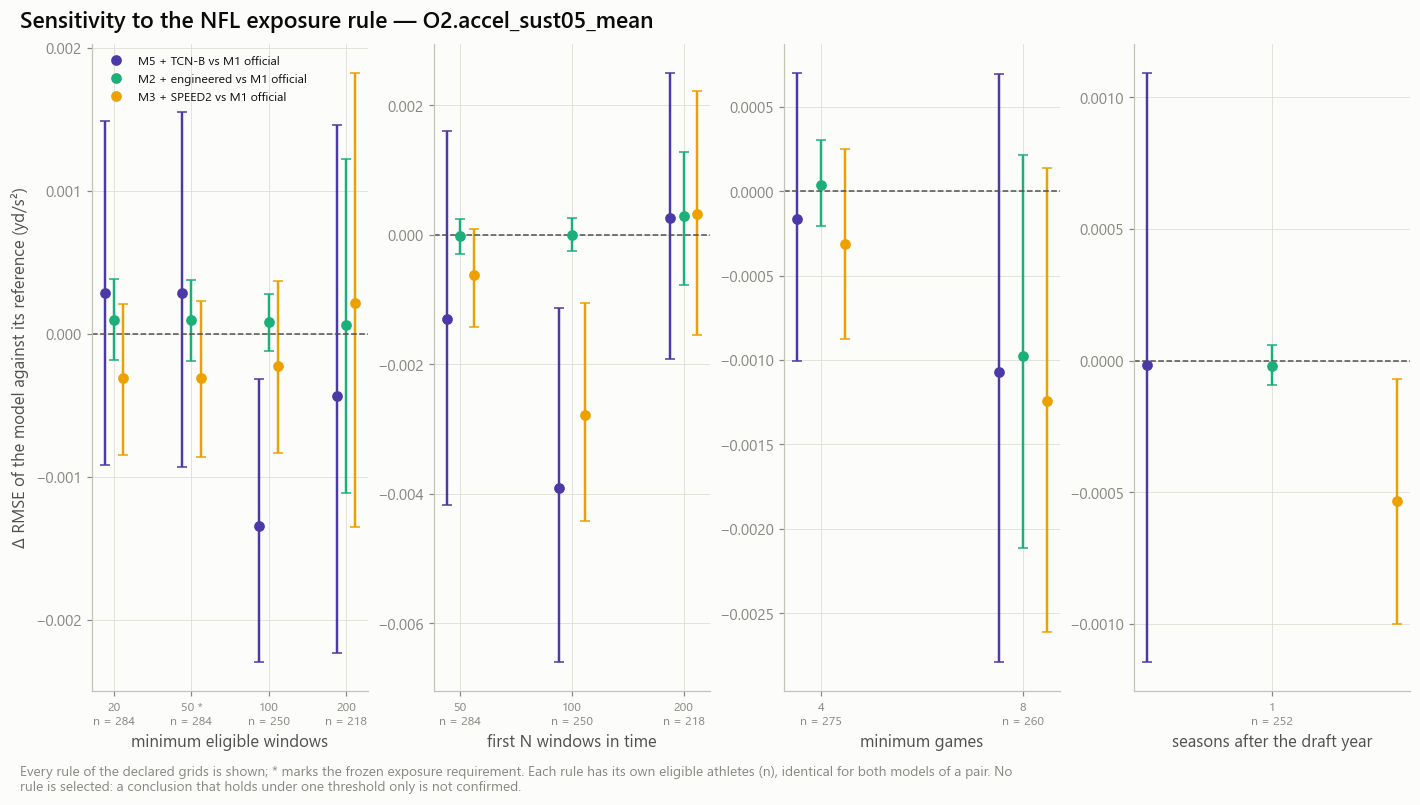

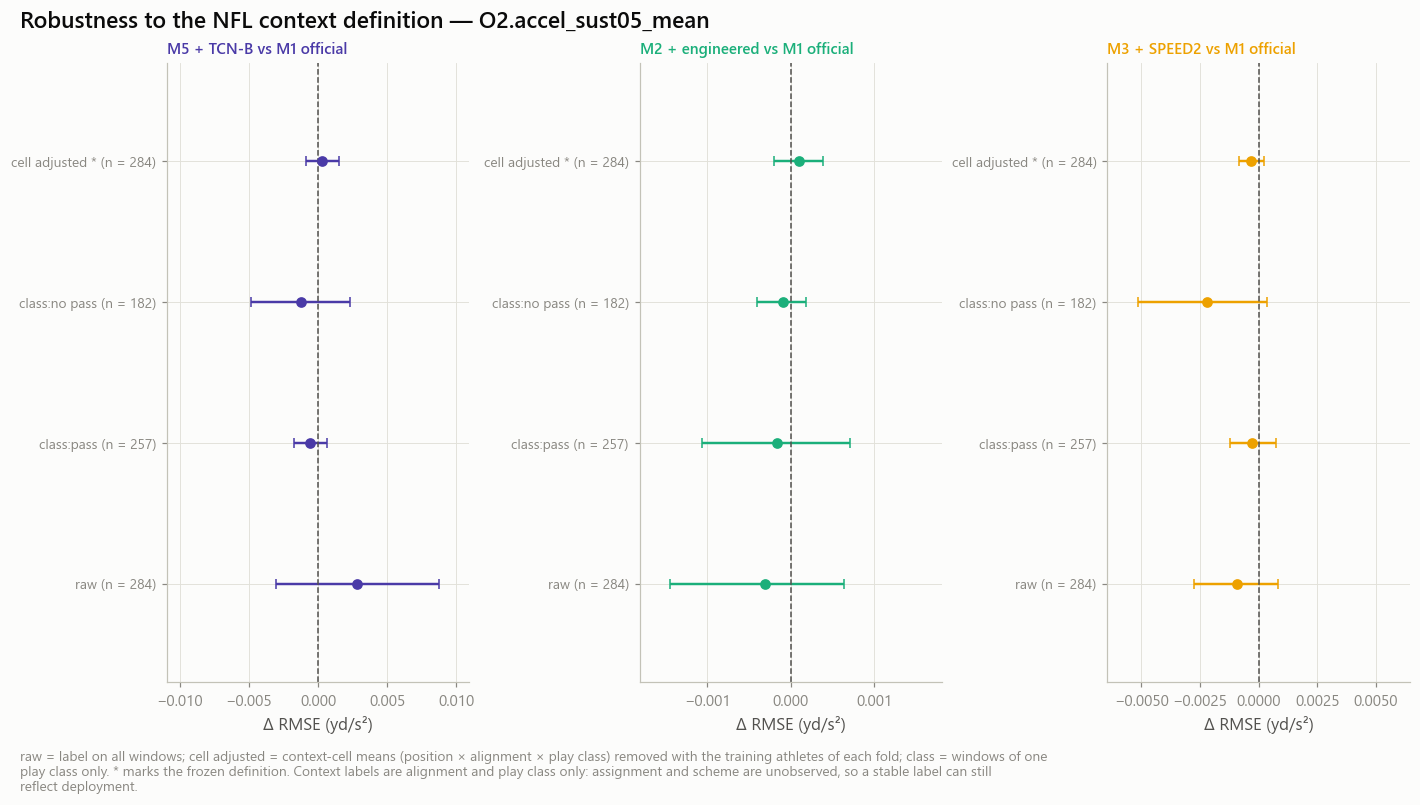

In [9]:
plan_sens = tx.sensitivity_plan(primary, tc)
SENS_C = [nm(c, 'sens') for c in OOF_C]

def build_sens():
    parts = [tm.run_analysis(p['analysis'], primary, d, tset, blocks, CORE_MODELS, tc, variant=p['variant'], adjustment=p['adjustment'],
                             min_windows=p['min_windows'], min_games=p['min_games']) for p in plan_sens]
    out = tm.concat(parts, OOF_C)
    return {nm(c, 'sens').name: out[c.name] for c in OOF_C}

se = store.build('OOF_SENS', SENS_C, build_sens, params={**BASE_PARAMS, 'plan': [{k: str(v) for k, v in p.items()} for p in plan_sens]},
                 files=[store.parquet(trp.named(trp.ATTEMPT_REP, 'outer')), store.nfl.parquet(no.plays_contract(ocfg)), store.parquet(tr.FOLDS)])
sens_oof = se[nm(tm.OOF, 'sens').name]
ev = tm.evaluate(sens_oof, PAIRS, tc, controls.seed) if sens_oof.height else {tm.PERF.name: tm.PERF.empty(), tm.PAIRED.name: tm.PAIRED.empty()}
sens_perf, sens_paired = save(ev[tm.PERF.name], nm(tm.PERF, 'sens')), save(ev[tm.PAIRED.name], nm(tm.PAIRED, 'sens'))

done = set(sens_oof['analysis'].unique().to_list())
display(Markdown(f'**{len(done)} of {len(plan_sens)} declared rules evaluated**; skipped for too few eligible athletes: '
                 f'{sorted(p["analysis"] for p in plan_sens if p["analysis"] not in done) or "none"}'))
SENS_PAIRS = [(m, tm.REFERENCE) for m in ('M5', 'M2', 'M3') if m in LADDER]
view = sens_paired.filter((pl.col('metric') == 'delta_rmse') & (pl.col('reference') == tm.REFERENCE) & pl.col('model').is_in([m for m, _ in SENS_PAIRS]))
with pl.Config(tbl_rows=80, float_precision=4, fmt_str_lengths=40):
    display(view.select('analysis', 'model', 'n_athletes', pl.col('estimate').alias('delta_rmse'), 'ci_lower', 'ci_upper', 'established', 'worse')
            .sort('model', 'analysis'))
    signs = view.filter(pl.col('estimate').is_not_null()).group_by('model').agg(pl.len().alias('rules'), (pl.col('estimate') > 0).sum().alias('rules_positive'),
                                                                                pl.col('established').sum().alias('rules_established'),
                                                                                pl.col('worse').sum().alias('rules_worse')).sort('model')
    display(Markdown('**Direction of Δ RMSE against M1 across all declared rules**'))
    display(signs)
store.show(tf.plot_exposure_sensitivity(sens_paired, plan_sens, P, SENS_PAIRS, U, primary.min_windows), 'AM06C_03_exposure_sensitivity',
           {'sensitivity': view.filter(pl.col('analysis').str.starts_with('exposure:'))}, publication=True, source='transfer_paired_comparisons_sens', n='each rule on its own eligible athletes')
store.show(tf.plot_context(sens_paired, P, SENS_PAIRS, U, primary.adjustment), 'AM06C_04_nfl_context_robustness',
           {'sensitivity': view.filter(pl.col('analysis').str.starts_with('context:'))}, source='transfer_paired_comparisons_sens', n='each rule on its own eligible athletes')

## 5. Matched-stopwatch athlete comparison — mandatory

This is the research question in its most direct form: *two prospects with similar official results — can a model tell which will move more in NFL games?*

- **Match rule (frozen in notebook 04B, before any NFL value):** same position group; official forty, 10-yard split and weight required, height when recorded; root-mean-square difference in within-position SD units inside the caliper; each athlete is paired with at most his k nearest. Scales come from the design-role athletes. NFL outcomes play no part in forming or selecting pairs.
- **Predictions are out of fold** (06B), so a pair is never scored by a model fitted on either of its athletes' labels.
- **Read-out:** share of pairs whose predicted difference has the sign of the observed NFL difference (0.5 = chance), correlation of predicted with observed differences, and each model against the official-only model M1 on the same pairs.
- **Uncertainty:** athletes are resampled (pairs reuse athletes); the reuse is reported.

By construction the official-only model has little to say inside matched pairs — that is the point of matching. The case studies at the end are the closest stopwatch matches, chosen by distance alone and **labelled illustrative**.

11:55:32 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:06C] transfer_matched_pairs: 833 rows → warehouse/gold/advanced_movement/transfer/transfer_matched_pairs.parquet
11:55:32 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:06C] transfer_matched_pair_predictions: 29,988 rows → warehouse/gold/advanced_movement/transfer/transfer_matched_pair_predictions.parquet
11:55:36 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:06C] transfer_matched_pair_summary: 36 rows → warehouse/gold/advanced_movement/transfer/transfer_matched_pair_summary.parquet


**Match rule:** {'version': '1', 'variables': ['cmb_forty', 'cmb_ten_yd_split', 'cmb_combine_weight', 'cmb_combine_height'], 'required': ['cmb_forty', 'cmb_ten_yd_split', 'cmb_combine_weight'], 'k_nearest': 5, 'caliper': 0.75, 'scale_role': 'design'} · scales (within-position SD, design athletes): {'cmb_forty': 0.159, 'cmb_ten_yd_split': 0.055, 'cmb_combine_weight': 16.271, 'cmb_combine_height': 1.647}

**833 matched pairs** of 275 distinct athletes (of 284); an athlete is in up to 14 pairs; 164 pairs share an outer fold, 274 a draft cohort

position_group,n_pairs,median_distance,median_abs_d_forty_s,median_abs_d_weight_lb
str,u32,f64,f64,f64
"""DB""",218,0.372084,0.05,5.0
"""DL""",179,0.506856,0.06,6.0
"""OL""",185,0.463582,0.06,6.0
"""TE""",58,0.57686,0.06,6.0
"""WR""",193,0.407064,0.05,5.0


**Ordering of matched pairs by model** — `O2.accel_sust05_mean` (intervals: athlete-cluster bootstrap)

model,n_pairs,n_athletes,max_reuse,concordance,concordance_lower,concordance_upper,corr,d_concordance,d_concordance_lower,d_concordance_upper
str,i64,i64,i64,f64,f64,f64,f64,f64,f64,f64
"""M0""",833,275,14,0.521,0.449,0.594,-0.119,0.020,-0.025,0.067
"""M1""",833,275,14,0.501,0.430,0.573,-0.142,null,null,null
"""M2""",833,275,14,0.505,0.436,0.577,-0.143,0.005,-0.014,0.025
"""M3""",833,275,14,0.510,0.443,0.583,-0.150,0.010,-0.010,0.031
"""M4""",833,275,14,0.510,0.442,0.580,-0.144,0.010,-0.013,0.035
"""M5""",833,275,14,0.496,0.425,0.568,-0.156,-0.005,-0.035,0.028
"""M5S""",833,275,14,0.507,0.437,0.577,-0.153,0.006,-0.021,0.036
"""M6""",833,275,14,0.499,0.433,0.569,-0.154,-0.001,-0.031,0.031
"""M7_PC2""",833,275,14,0.505,0.435,0.576,-0.141,0.005,-0.012,0.023


**Case studies — ILLUSTRATIVE ONLY.** The closest stopwatch-and-body matches (chosen by distance alone, before looking at any prediction or outcome). A few pairs cannot support or refute anything.

pair_id,position_group,athlete_a,athlete_b,forty_a,forty_b,ten_a,ten_b,weight_a,weight_b,distance,predicted_diff_M1,predicted_diff_M5,actual_diff,status
i64,str,str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str
506,"""DL""","""Laiatu Latu""","""Tyler Baron""",4.640,4.620,1.620,1.610,259.000,258.000,0.121,0.043,0.039,-0.186,"""illustrative only"""
588,"""TE""","""Ben Sinnott""","""Cade Stover""",4.680,4.650,1.590,1.590,250.000,247.000,0.132,-0.030,-0.027,-0.177,"""illustrative only"""
765,"""DL""","""Leonard Taylor""","""Joshua Farmer""",5.120,5.110,1.760,1.770,303.000,305.000,0.137,-0.024,-0.006,0.142,"""illustrative only"""
531,"""DB""","""Terrion Arnold""","""Renardo Green""",4.500,4.490,1.540,1.530,189.000,186.000,0.138,0.020,0.035,-0.199,"""illustrative only"""
691,"""TE""","""Ja'Tavion Sanders""","""Cade Stover""",4.690,4.650,1.590,1.590,245.000,247.000,0.140,0.066,0.056,-0.195,"""illustrative only"""
254,"""DB""","""Chamarri Conner""","""R.J. Mickens""",4.510,4.490,1.560,1.550,202.000,199.000,0.144,-0.049,-0.048,0.082,"""illustrative only"""


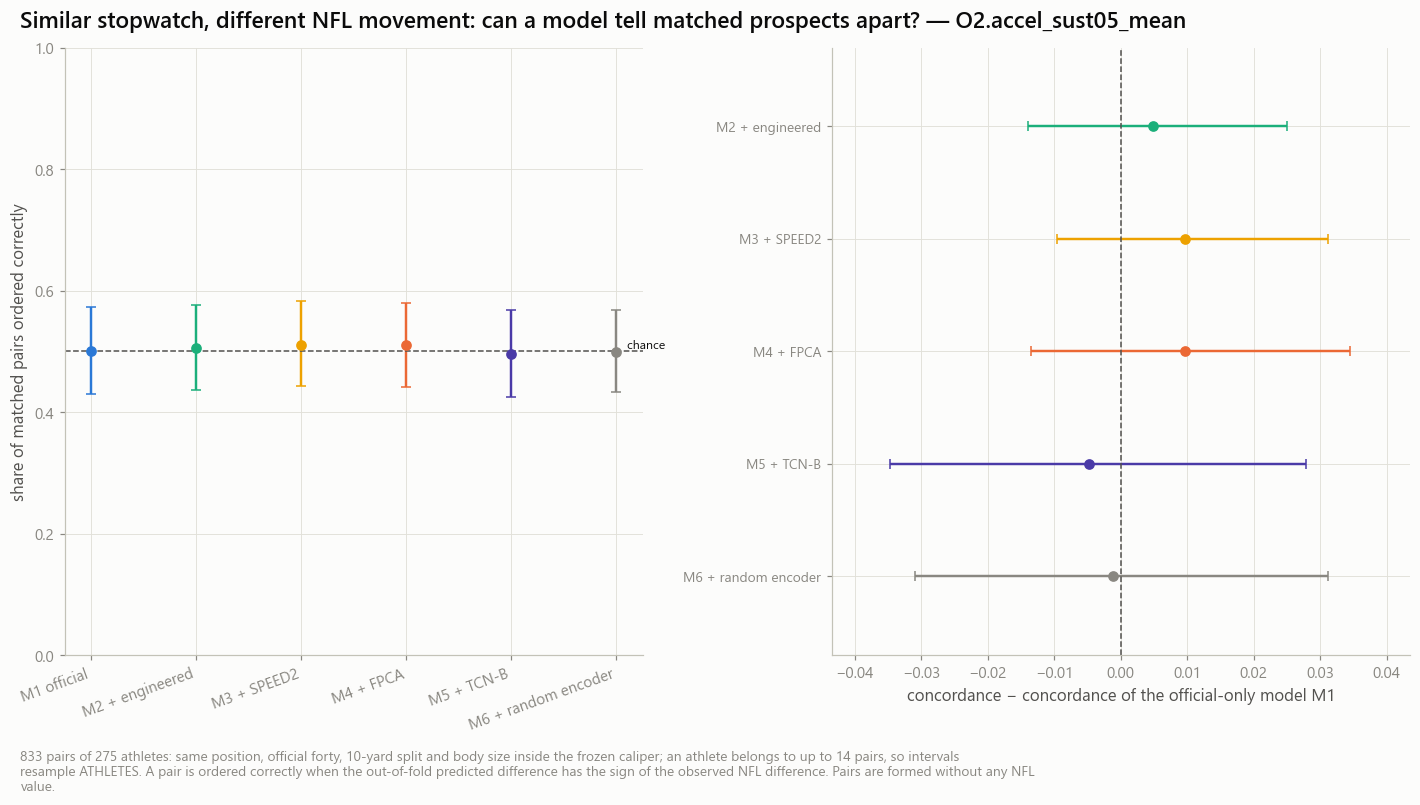

In [10]:
meta = fe.Meta(windows, athletes)
roles = {int(i): str(r) for i, r in splits.filter(pl.col('repeat') == 0).select('nfl_id', 'design_role').iter_rows()}
mc = rb.MatchConfig()                      # the pre-declared rule of notebook 04B: variables, required, k nearest, caliper, scale role
scales = rb.matching_scales(meta, roles, mc)
pairs = save(tx.matched_pairs(dP, meta, scales, mc), tx.PAIRS)
pair_pred = save(tx.pair_predictions(pairs, oof), tx.PAIR_PRED)
pair_sum = save(tx.pair_summary(pairs, pair_pred, tc, controls.seed), tx.PAIR_SUMMARY)

display(Markdown(f'**Match rule:** {mc.params()} · scales (within-position SD, design athletes): { {k: round(v, 3) for k, v in scales.items()} }'))
if pairs.height:
    in_pairs = pl.concat([pairs['nfl_id_a'], pairs['nfl_id_b']])
    display(Markdown(f'**{pairs.height} matched pairs** of {in_pairs.n_unique()} distinct athletes (of {dP.n}); an athlete is in up to '
                     f'{in_pairs.value_counts()["count"].max()} pairs; {int(pairs["same_fold"].sum())} pairs share an outer fold, '
                     f'{int(pairs["same_cohort"].sum())} a draft cohort'))
    display(pairs.group_by('position_group').agg(pl.len().alias('n_pairs'), pl.col('distance').median().alias('median_distance'),
                                                 pl.col('d_forty').abs().median().alias('median_abs_d_forty_s'),
                                                 pl.col('d_weight').abs().median().alias('median_abs_d_weight_lb')).sort('position_group'))
    with pl.Config(tbl_rows=40, float_precision=3):
        display(Markdown(f'**Ordering of matched pairs by model** — `{P}` (intervals: athlete-cluster bootstrap)'))
        display(pair_sum.filter(pl.col('target_id') == P).select('model', 'n_pairs', 'n_athletes', 'max_reuse', 'concordance', 'concordance_lower',
                                                                 'concordance_upper', 'corr', 'd_concordance', 'd_concordance_lower', 'd_concordance_upper'))
    cases = tx.case_studies(pairs, pair_pred, athletes, P, [m for m in ('M1', 'M5') if m in LADDER], tc.case_studies)
    display(Markdown('**Case studies — ILLUSTRATIVE ONLY.** The closest stopwatch-and-body matches (chosen by distance alone, before looking at any '
                     'prediction or outcome). A few pairs cannot support or refute anything.'))
    with pl.Config(fmt_str_lengths=40, float_precision=3):
        display(cases)
else:
    cases = pl.DataFrame(schema={'status': pl.String})
    display(Markdown('*No pair of athletes of the same position lies inside the caliper: the matched comparison cannot be evaluated on this cohort.*'))
store.show(tf.plot_matched(pair_sum, P, [m for m in ('M1', 'M2', 'M3', 'M4', 'M5', 'M6') if m in LADDER]), 'AM06C_05_matched_stopwatch_player_comparisons',
           {'summary': pair_sum}, publication=True, source='transfer_matched_pair_predictions', n=f'{pairs.height} matched pairs')

## 6. Physical transfer mechanism

*Does Combine speed development over a defined speed interval relate to NFL acceleration?* This uses the **frozen** physical feature(s) of the shortlist (and the speed control for contrast) against every frozen NFL target — potentially more interpretable than a learned fingerprint.

- association **within position group** (Spearman of position-centred values);
- association after position, draft cohort and the official forty, 10-yard split and weight (partial correlation, athlete bootstrap with the adjustment refitted in each resample).

These are in-sample and descriptive. The held-out answer to *does it add predictive value* is model M2 against M1 (06B), repeated in the last column. The Combine interval and the NFL starting-speed band of a target are stated side by side: when they differ, the comparison is across speed ranges and is said so. A direction is expected, not assumed: a *shorter* time between two speeds means *more* acceleration.

11:55:47 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:06C] transfer_physical_mechanism: 6 rows → warehouse/gold/advanced_movement/transfer/transfer_physical_mechanism.parquet


**Frozen physical Combine features against frozen NFL targets** (unit: athlete; in-sample association + held-out increment)

feature_id,target_id,n_athletes,spearman_within_position,partial_r,partial_lower,partial_upper,heldout_delta_rmse_M2_vs_M1,heldout_lower,heldout_upper,note
str,str,i64,f64,f64,f64,f64,f64,f64,f64,str
"""F6.forty.time_v4_to_v8_s""","""O2.accel_sust05_mean""",284,-0.112,-0.030,-0.133,0.071,0.000,-0.000,0.000,"""NFL starting-speed range of the target: any"""
"""F6.forty.time_v4_to_v8_s""","""O3.band_acc_v0_2_mean""",284,-0.322,0.049,-0.054,0.145,-0.000,-0.002,0.001,"""NFL starting-speed range of the target: [0, 2) yd/s"""
"""F6.forty.time_v4_to_v8_s""","""O1.speed_p90_mean""",284,-0.297,0.025,-0.070,0.126,0.000,-0.001,0.001,"""NFL starting-speed range of the target: any"""
"""F2.forty.p95_speed""","""O2.accel_sust05_mean""",284,0.122,-0.046,-0.187,0.096,0.000,-0.000,0.000,"""NFL starting-speed range of the target: any"""
"""F2.forty.p95_speed""","""O3.band_acc_v0_2_mean""",284,0.403,-0.032,-0.172,0.102,-0.000,-0.002,0.001,"""NFL starting-speed range of the target: [0, 2) yd/s"""
"""F2.forty.p95_speed""","""O1.speed_p90_mean""",284,0.448,0.152,0.037,0.263,0.000,-0.001,0.001,"""NFL starting-speed range of the target: any"""


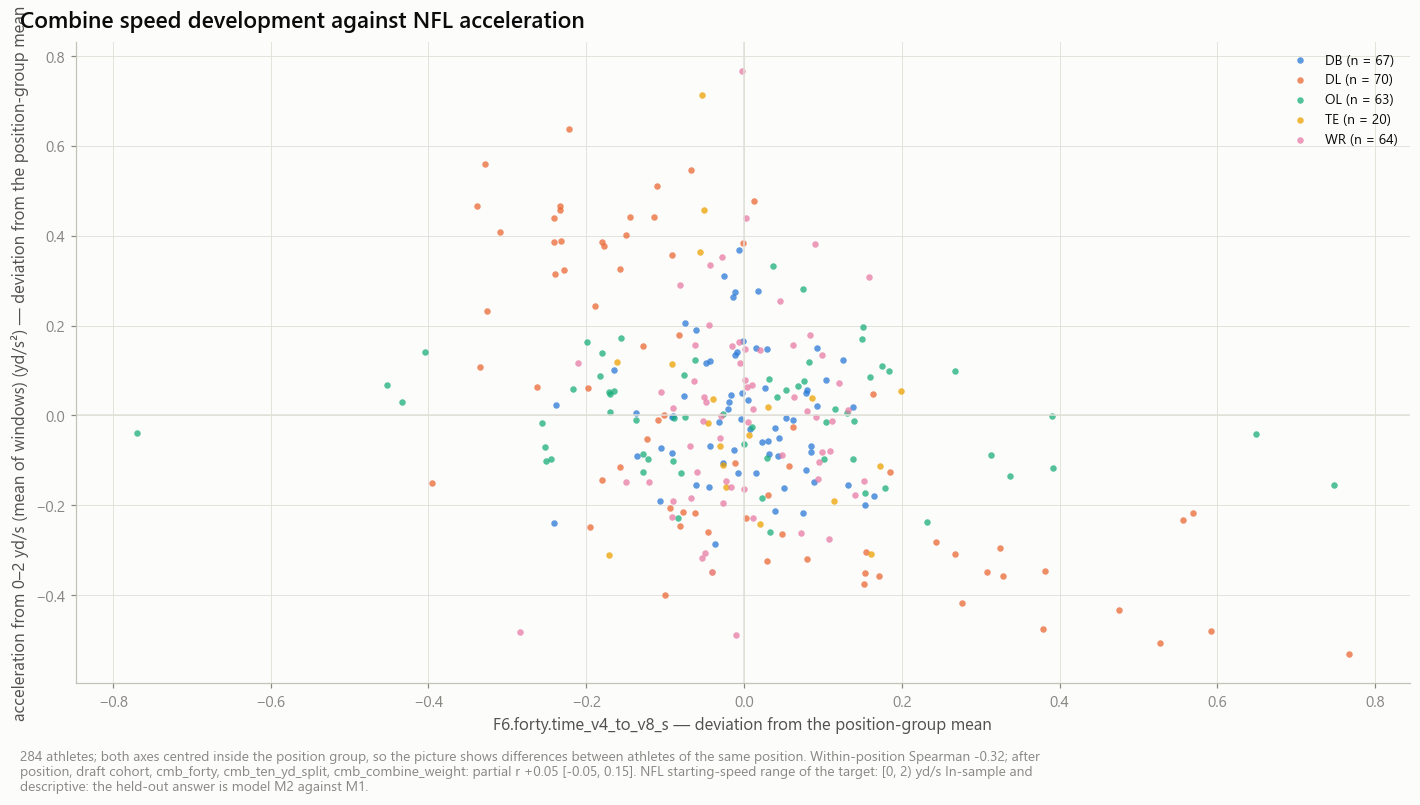

In [11]:
phys_ids = [*families['ENG'], *[f for f in families['SPEED_CONTROL'] if f not in families['ENG']]]
ath_feat = (attempt_values.filter(pl.col('feature_id').is_in(phys_ids) & pl.col('value').is_not_null())
            .group_by('feature_id', 'nfl_id').agg(pl.col('value').mean().alias('value')))          # athlete = mean of his attempts (frozen rule)

def aligned(df, ids, col):
    m = dict(df.select('nfl_id', col).iter_rows())
    return np.array([m.get(int(i), np.nan) if m.get(int(i)) is not None else np.nan for i in ids], dtype=float)

feat = {f: aligned(ath_feat.filter(pl.col('feature_id') == f), d.ids, 'value') for f in phys_ids}
lab = {t.target_id: aligned(labels.filter(pl.col('target_id') == t.target_id), d.ids, 'y_descriptive') for t in targets}
spec = {s.outcome_id: s for s in no.outcome_specs(ocfg)}
notes = {(f, t.target_id): f'NFL starting-speed range of the target: {spec[t.target_id].start_speed}' for f in phys_ids for t in targets}
mech = save(tx.mechanism_table(feat, lab, d, [fe.FORTY, fe.TEN, fe.WEIGHT], tc, controls.seed, notes), tx.MECH)

m2 = paired_all.filter((pl.col('analysis') == tm.PRIMARY) & (pl.col('cohort') == tm.PRIMARY) & (pl.col('model') == 'M2') & (pl.col('reference') == 'M1')
                       & (pl.col('metric') == 'delta_rmse')).select('target_id', pl.col('estimate').alias('heldout_delta_rmse_M2_vs_M1'),
                                                                    pl.col('ci_lower').alias('heldout_lower'), pl.col('ci_upper').alias('heldout_upper'))
with pl.Config(tbl_rows=40, float_precision=3, fmt_str_lengths=90):
    display(Markdown('**Frozen physical Combine features against frozen NFL targets** (unit: athlete; in-sample association + held-out increment)'))
    display(mech.join(m2, on='target_id', how='left').select('feature_id', 'target_id', 'n_athletes', 'spearman_within_position', 'partial_r',
                                                             'partial_lower', 'partial_upper', 'heldout_delta_rmse_M2_vs_M1', 'heldout_lower',
                                                             'heldout_upper', 'note'))
if families['ENG']:
    f0 = families['ENG'][0]
    t0 = next((t for t in targets if t.study_role == 'secondary_speed_conditioned'), primary)      # the speed-conditioned target when one is frozen
    row = mech.filter((pl.col('feature_id') == f0) & (pl.col('target_id') == t0.target_id))
    store.show(tf.plot_mechanism(feat[f0], lab[t0.target_id], d.position, f0, f'{t0.label} ({t0.unit})', row.row(0, named=True) if row.height else None),
               'AM06C_06_combine_acceleration_vs_nfl_acceleration', {'mechanism': mech}, publication=True,
               source='atlas_attempt_features + transfer_oof_targets', n=f'{int((np.isfinite(feat[f0]) & np.isfinite(lab[t0.target_id])).sum())} athletes')
else:
    display(Markdown('*The frozen shortlist holds no engineered acceleration feature (empty slot): the mechanism figure cannot be drawn.*'))

## 7. TCN-B added value

The encoder against official tests (M1), SPEED2 (M3), engineered acceleration (M2), FPCA (M4) and an untrained encoder (M6) is the content of 06B figure 8 and of the table carried into section 0. Three additions here:

1. **Training-seed replicates.** The shortlist froze TCN-B at its pre-declared first seed and required the transfer result to be reported on the other seeds too. Each replicate is a full set of fold encoders (reused from 04B where the 06A audit cleared them, otherwise trained here). No seed is selected.
2. **How much the encoder re-orders prospects** inside a position group, relative to the official model — a description of the difference between two models, not evidence that the new order is better.
3. **What the read-out uses** — only if a gain is established (or `RUN_ATTRIBUTION = 'always'`): for the training athletes of a fold, each slice of the speed-by-distance curve is hidden in turn and the change of the fitted read-out is recorded. This says which part of the run the *prediction* depends on. It is not a physical interpretation of an embedding coordinate, and it is not a causal statement.

11:55:51 | INFO    | nflbdb.research.advanced_movement.artifacts | [advanced_movement:REP_SEEDS] computing (never run)
11:55:52 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:REP_SEEDS] transfer_attempt_representations_seeds: 63,440 rows → warehouse/gold/advanced_movement/transfer/transfer_attempt_representations_seeds.parquet
11:55:52 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:REP_SEEDS] transfer_encoder_fits_seeds: 10 rows → warehouse/gold/advanced_movement/transfer/transfer_encoder_fits_seeds.parquet


family,fold,source,seed,n_overlap,n_heldout_valid,best_epoch
str,i64,str,i64,i64,i64,i64
"""TCN_s1""",0,"""reused_checkpoint""",20261012,0,158,113
"""TCN_s1""",1,"""reused_checkpoint""",20261012,0,162,64
"""TCN_s1""",2,"""reused_checkpoint""",20261012,0,163,59
"""TCN_s1""",3,"""reused_checkpoint""",20261012,0,157,200
"""TCN_s1""",4,"""reused_checkpoint""",20261012,0,153,107
"""TCN_s2""",0,"""reused_checkpoint""",20261013,0,158,123
"""TCN_s2""",1,"""reused_checkpoint""",20261013,0,162,39
"""TCN_s2""",2,"""reused_checkpoint""",20261013,0,163,128
"""TCN_s2""",3,"""reused_checkpoint""",20261013,0,157,89


11:55:52 | INFO    | nflbdb.research.advanced_movement.artifacts | [advanced_movement:OOF_SEEDS] computing (never run)
11:55:58 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:OOF_SEEDS] transfer_oof_predictions_seeds: 1,136 rows → warehouse/gold/advanced_movement/transfer/transfer_oof_predictions_seeds.parquet
11:55:58 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:OOF_SEEDS] transfer_oof_targets_seeds: 568 rows → warehouse/gold/advanced_movement/transfer/transfer_oof_targets_seeds.parquet
11:55:58 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:OOF_SEEDS] transfer_fold_preprocessing_seeds: 420 rows → warehouse/gold/advanced_movement/transfer/transfer_fold_preprocessing_seeds.parquet
11:56:01 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:06C] transfer_paired_comparisons_seeds: 12 rows → warehouse/gold/advanced_movement/transfer/transfer_paired_comparisons_seeds.parquet


**TCN-B against M1 by training seed** — `O2.accel_sust05_mean` (`seed:TCN` = the pre-declared primary seed of 06B)

analysis,n_athletes,delta_rmse,ci_lower,ci_upper,relative,established,worse
str,i64,f64,f64,f64,f64,bool,bool
"""seed:TCN""",284,0.0003,-0.0008,0.0015,0.0016,false,false
"""seed:TCN_s1""",284,-0.0003,-0.0011,0.0006,-0.0014,false,false
"""seed:TCN_s2""",284,-0.0002,-0.0011,0.0007,-0.0012,false,false


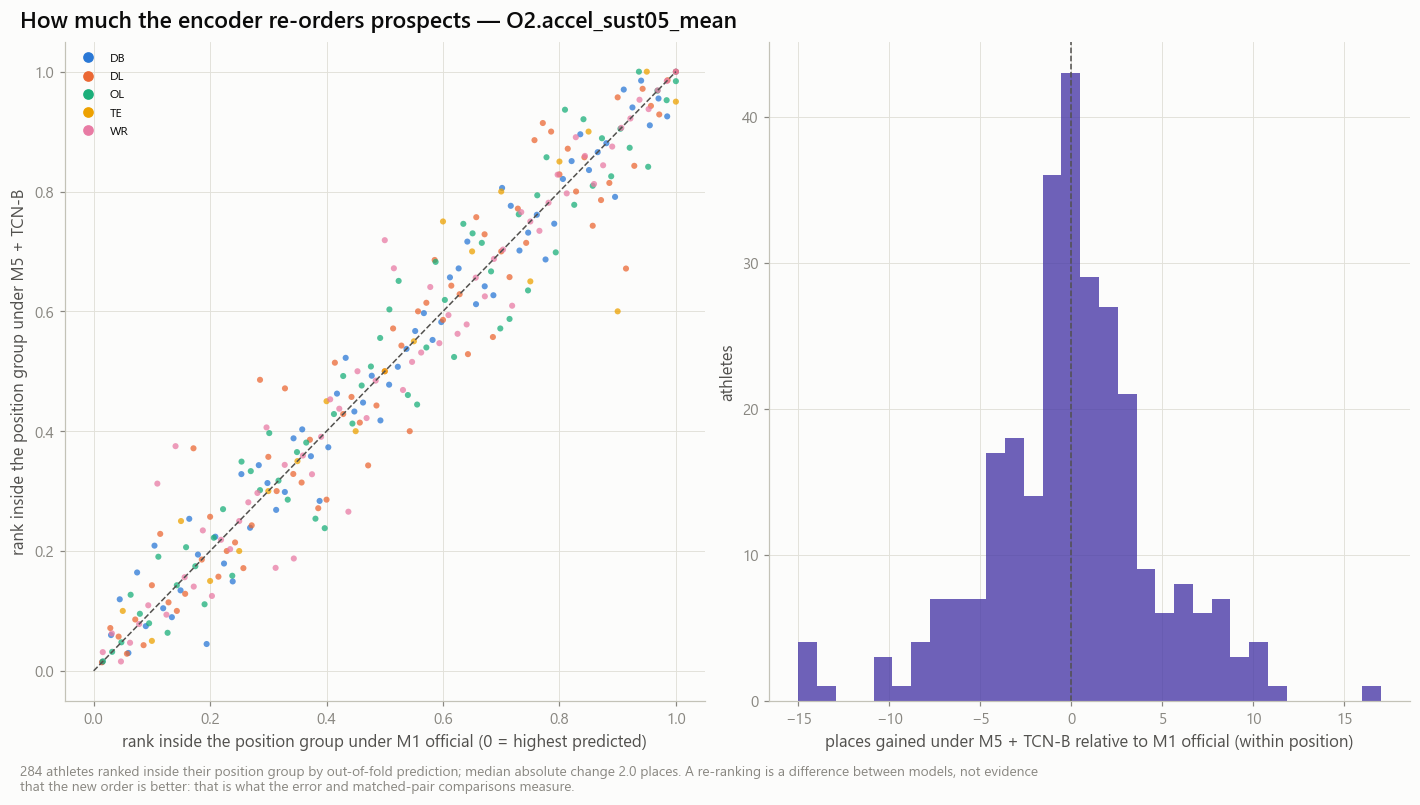

*Attribution not run: M5 vs M1 established = False, RUN_ATTRIBUTION = `if_gain`. Explaining a gain that is not established would be explaining noise.*

In [ ]:
seed_paired = paired.filter((pl.col('target_id') == P) & (pl.col('model') == 'M5') & (pl.col('reference') == tm.REFERENCE)).with_columns(
    pl.lit('seed:TCN').alias('analysis'))
if RUN_SEEDS and 'M5' in LADDER:
    reps = tuple((f'TCN_s{i + 1}', int(s)) for i, s in enumerate(tc.replicate_seeds))
    reuse = {(fam, f): str(cfg.paths.project_root / p) for i, (fam, _) in enumerate(reps)
             for f, p in tr.reusable_checkpoints(compat, f'{families["TCN"]}_s{i + 1}').items() if f in FOLD_IDS}
    plan_seeds = trp.RepPlan(tcfg, fcfg, FPCA_K, controls.seed, families=tuple(f for f, _ in reps), compact_dims=(), replicates=reps)
    rep_seeds = trp.build_representations(store, 'REP_SEEDS', 'seeds', curves, enc_splits, FOLD_IDS, plan_seeds, {}, device, reuse, 'outer',
                                          {**REP_PARAMS, 'replicates': [list(r) for r in reps]}, REP_FILES)
    display(rep_seeds[trp.ENC_FITS.name].select('family', 'fold', 'source', 'seed', 'n_overlap', 'n_heldout_valid', 'best_epoch').sort('family', 'fold'))
    blocks_seeds = tm.RepBlocks(rep_seeds[trp.ATTEMPT_REP.name], ORDER, scheme='outer', how=tc.aggregation)
    SEED_C = [nm(c, 'seeds') for c in OOF_C]

    def build_seeds():
        parts = []
        for fam, _ in reps:
            ok = tm.common_support(dP, blocks_seeds, [fam])
            dd = dP.keep_ids(ok.filter(pl.col('in_paired_cohort'))['nfl_id'].to_list())
            parts.append(tm.run_analysis(f'seed:{fam}', primary, dd, tset, blocks_seeds, [LADDER['M1'], replace(LADDER['M5'], families=(fam,))], tc))
        out = tm.concat(parts, OOF_C)
        return {nm(c, 'seeds').name: out[c.name] for c in OOF_C}
    so = store.build('OOF_SEEDS', SEED_C, build_seeds, params={**BASE_PARAMS, 'replicates': [list(r) for r in reps]},
                     files=[store.parquet(trp.named(trp.ATTEMPT_REP, 'seeds')), store.parquet(tr.FOLDS)])
    seeds_oof = so[nm(tm.OOF, 'seeds').name]
    if seeds_oof.height:
        seed_paired = pl.concat([seed_paired, tm.evaluate(seeds_oof, [('M5', tm.REFERENCE)], tc, controls.seed)[tm.PAIRED.name]])
seed_paired = save(seed_paired, nm(tm.PAIRED, 'seeds'))
display(Markdown(f'**TCN-B against M1 by training seed** — `{P}` (`seed:TCN` = the pre-declared primary seed of 06B)'))
with pl.Config(float_precision=4):
    display(seed_paired.filter(pl.col('metric') == 'delta_rmse').select('analysis', 'n_athletes', pl.col('estimate').alias('delta_rmse'), 'ci_lower',
                                                                        'ci_upper', 'relative', 'established', 'worse').sort('analysis'))

oofP = oof.filter(pl.col('target_id') == P)
if 'M5' in LADDER:
    shift = tx.rank_shift(oofP, tm.REFERENCE, 'M5')
    store.show(tf.plot_rank_shift(shift, tm.REFERENCE, 'M5', P), 'AM06C_07_model_predicted_athlete_ranking_differences', {'ranks': shift}, source=SRC, n=NTXT)

main_row = paired.filter((pl.col('target_id') == P) & (pl.col('model') == 'M5') & (pl.col('reference') == tm.REFERENCE) & (pl.col('metric') == 'delta_rmse'))
GAIN = bool(main_row.height and main_row['established'][0])
if RUN_ATTRIBUTION == 'always' or (RUN_ATTRIBUTION == 'if_gain' and GAIN):
    prof = []
    for r in enc_fits.filter((pl.col('family') == 'TCN') & (pl.col('checkpoint') != '')).iter_rows(named=True):
        t = tcn.load_checkpoint(Path(r['checkpoint']))
        train_ids = dP.ids[dP.fold != r['fold']]                                   # TRAINING athletes of the fold only
        w, mu, sd = tx.tcn_readout(prep, P, r['fold'])
        prof.append(trp.occlusion_profile(t, curves, train_ids, w, mu, sd, device=device).with_columns(pl.lit(r['fold']).alias('fold')))
    if prof:
        occl = pl.concat(prof)
        display(Markdown(f'**Read-out sensitivity to hidden slices of the curve** (training athletes; {U}; axis = recorded distance in yards). '
                         'Descriptive: which part of the run the prediction depends on.'))
        display(occl.group_by('bin').agg(pl.col('axis_lo').first(), pl.col('axis_hi').first(), pl.col('rms_shift').mean().alias('mean_rms_shift'),
                                         pl.col('rms_shift').min().alias('min_over_folds'), pl.col('rms_shift').max().alias('max_over_folds')).sort('bin'))
        if controls.save_tables:
            occl.write_csv(store.tables_dir / 'transfer_tcn_occlusion_profile.csv')
    else:
        display(Markdown('*No fold encoder file is recorded (SAVE_MODELS was off in 06B): the read-out analysis cannot run.*'))
else:
    display(Markdown(f'*Attribution not run: M5 vs M1 established = {GAIN}, RUN_ATTRIBUTION = `{RUN_ATTRIBUTION}`. Explaining a gain that is not '
                     'established would be explaining noise.*'))

## 8. Null controls

Checks of the **pipeline**; they do not replace held-out validation.

- **Random encoder (M6)** — already in the benchmark: the same curve through the same code path with untrained weights.
- **Outcome permutation** — labels are permuted between athletes *within position group* and the whole out-of-fold loop is rerun: position means survive, every athlete-level link is broken. The observed Δ RMSE should lie in the upper tail if there is signal; a pipeline that shows a 'gain' on permuted labels is leaking.
- **Athlete-linkage permutation** — the representation rows are permuted between athletes within position while labels and official results stay: a gain that comes from the athlete's own run must vanish.

The same checks are run for the official baseline against M0, as a positive control of the procedure.

[13:47:07] ======================================================================
[13:47:07] MILESTONE 06C — COMPUTATION MONITOR
[13:47:07] ======================================================================
[13:47:07] Run mode: full
[13:47:07] Permutations enabled: True
[13:47:07] Permutations per test: 200
[13:47:07] Model comparisons: 5
[13:47:07] Permutation tasks: 9
[13:47:07] Total permutation iterations: 1,800

Planned permutation tasks:
  01/09 | M1 vs M0 | mode=outcome | n=200
  02/09 | M2 vs M1 | mode=outcome | n=200
  03/09 | M2 vs M1 | mode=linkage | n=200
  04/09 | M3 vs M1 | mode=outcome | n=200
  05/09 | M3 vs M1 | mode=linkage | n=200
  06/09 | M4 vs M1 | mode=outcome | n=200
  07/09 | M4 vs M1 | mode=linkage | n=200
  08/09 | M5 vs M1 | mode=outcome | n=200
  09/09 | M5 vs M1 | mode=linkage | n=200



13:47:07 | INFO    | nflbdb.research.advanced_movement.artifacts | [advanced_movement:PERMUTATION] computing (never run)


[13:47:07] START | PERM 1/9 | M1 vs M0 | outcome
[13:47:37] RUNNING | PERM 1/9 | M1 vs M0 | outcome | Elapsed: 30s | Still waiting for computation
[13:48:07] RUNNING | PERM 1/9 | M1 vs M0 | outcome | Elapsed: 1m 00s | Still waiting for computation
[13:48:37] RUNNING | PERM 1/9 | M1 vs M0 | outcome | Elapsed: 1m 30s | Still waiting for computation
[13:49:07] RUNNING | PERM 1/9 | M1 vs M0 | outcome | Elapsed: 2m 00s | Still waiting for computation
[13:49:37] RUNNING | PERM 1/9 | M1 vs M0 | outcome | Elapsed: 2m 30s | Still waiting for computation
[13:50:07] RUNNING | PERM 1/9 | M1 vs M0 | outcome | Elapsed: 3m 00s | Still waiting for computation
[13:50:37] RUNNING | PERM 1/9 | M1 vs M0 | outcome | Elapsed: 3m 30s | Still waiting for computation
[13:51:07] RUNNING | PERM 1/9 | M1 vs M0 | outcome | Elapsed: 4m 00s | Still waiting for computation
[13:51:38] RUNNING | PERM 1/9 | M1 vs M0 | outcome | Elapsed: 4m 30s | Still waiting for computation
[13:52:08] RUNNING | PERM 1/9 | M1 vs M0 | ou

model,reference,mode,observed,null_mean,null_q95,p_value,n_perm
str,str,str,f64,f64,f64,f64,i64
"""M1""","""M0""","""outcome""",0.0003,-0.0000,0.0011,0.2189,200


[13:54:18] START | PERM 2/9 | M2 vs M1 | outcome
[13:54:48] RUNNING | PERM 2/9 | M2 vs M1 | outcome | Elapsed: 30s | Still waiting for computation
[13:55:18] RUNNING | PERM 2/9 | M2 vs M1 | outcome | Elapsed: 1m 00s | Still waiting for computation
[13:55:48] RUNNING | PERM 2/9 | M2 vs M1 | outcome | Elapsed: 1m 30s | Still waiting for computation
[13:56:18] RUNNING | PERM 2/9 | M2 vs M1 | outcome | Elapsed: 2m 00s | Still waiting for computation
[13:56:48] RUNNING | PERM 2/9 | M2 vs M1 | outcome | Elapsed: 2m 30s | Still waiting for computation
[13:57:19] RUNNING | PERM 2/9 | M2 vs M1 | outcome | Elapsed: 3m 00s | Still waiting for computation
[13:57:49] RUNNING | PERM 2/9 | M2 vs M1 | outcome | Elapsed: 3m 31s | Still waiting for computation
[13:58:19] RUNNING | PERM 2/9 | M2 vs M1 | outcome | Elapsed: 4m 01s | Still waiting for computation
[13:58:49] RUNNING | PERM 2/9 | M2 vs M1 | outcome | Elapsed: 4m 31s | Still waiting for computation
[13:59:19] RUNNING | PERM 2/9 | M2 vs M1 | ou

...

**Permutation checks** — `O2.accel_sust05_mean` | 200 permutations per test | 9 tasks

model,reference,mode,observed,null_mean,null_q95,p_value,n_perm
str,str,str,f64,f64,f64,f64,i64
"""M1""","""M0""","""outcome""",0.0003,-0.0000,0.0011,0.2189,200
"""M2""","""M1""","""linkage""",0.0001,0.0000,0.0006,0.2289,200
"""M2""","""M1""","""outcome""",0.0001,-0.0000,0.0003,0.1045,200
"""M3""","""M1""","""linkage""",-0.0003,-0.0000,0.0007,0.8060,200
"""M3""","""M1""","""outcome""",-0.0003,-0.0000,0.0004,0.9652,200
"""M4""","""M1""","""linkage""",-0.0003,0.0000,0.0012,0.7264,200
"""M4""","""M1""","""outcome""",-0.0003,0.0000,0.0008,0.8458,200
"""M5""","""M1""","""linkage""",0.0003,-0.0004,0.0011,0.2338,200
"""M5""","""M1""","""outcome""",0.0003,-0.0000,0.0011,0.1692,200


[14:40:27] ======================================================================
[14:40:27] BOOTSTRAP CI STABILITY
[14:40:27] ======================================================================
[14:40:27] Model comparison: M5 vs M1
[14:40:27] Budgets: (200, 500, 1000, 2000, 4000)
[14:40:27] Total requested across budgets: 7,700
[14:40:27] Note: actual draw count depends on the ci_stability() implementation.
[14:40:27] START | Bootstrap CI stability
[14:40:28] DONE | Bootstrap CI stability | Duration: 0s


14:40:28 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:06C] transfer_ci_stability: 25 rows → warehouse/gold/advanced_movement/transfer/transfer_ci_stability.parquet


[14:40:28] Generating CI stability figure...


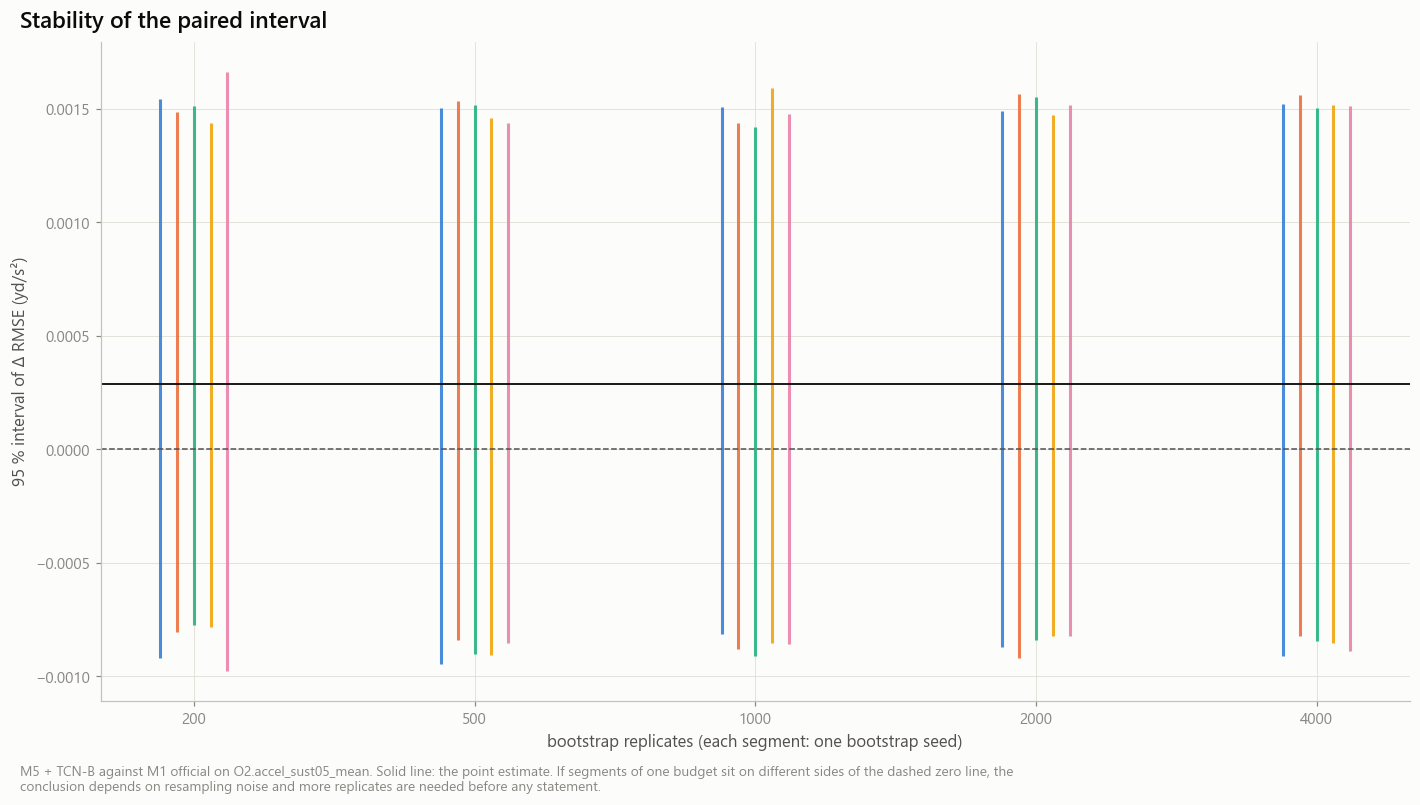

[14:40:29] MILESTONE 06C CELL COMPLETED


In [14]:
# ================================================================
# AM06C — PERMUTATION TESTS + CI STABILITY
# Detailed progress, timing, ETA, and heartbeat monitoring
# ================================================================

import time
import threading
from datetime import datetime
import numpy as np
import polars as pl
from IPython.display import display, Markdown

# ------------------------------------------------
# 0. MONITORING CONFIGURATION
# ------------------------------------------------

HEARTBEAT_SECONDS = 30

PERM_PAIRS = [
    (m, r)
    for m, r in (
        ("M1", "M0"),
        ("M2", "M1"),
        ("M3", "M1"),
        ("M4", "M1"),
        ("M5", "M1"),
    )
    if m in LADDER and r in LADDER
]

PERM_TASKS = [
    (pair, mode)
    for pair in PERM_PAIRS
    for mode in (
        ("outcome", "linkage")
        if LADDER[pair[0]].families
        else ("outcome",)
    )
]


def log_progress(message):
    timestamp = datetime.now().strftime("%H:%M:%S")
    print(f"[{timestamp}] {message}", flush=True)


def format_duration(seconds):
    seconds = max(0, int(seconds))
    hours, rem = divmod(seconds, 3600)
    minutes, secs = divmod(rem, 60)

    if hours:
        return f"{hours}h {minutes:02d}m {secs:02d}s"
    if minutes:
        return f"{minutes}m {secs:02d}s"
    return f"{secs}s"


def monitored_call(label, fn, interval=30):
    """
    Execute fn() normally while printing periodic heartbeat messages.

    A heartbeat confirms that the Python call has not returned.
    It does NOT prove that individual permutations are progressing.
    """

    stop_event = threading.Event()
    start = time.perf_counter()

    log_progress(f"START | {label}")

    def heartbeat():
        while not stop_event.wait(interval):
            elapsed = time.perf_counter() - start

            log_progress(
                f"RUNNING | {label} | "
                f"Elapsed: {format_duration(elapsed)} | "
                "Still waiting for computation"
            )

    thread = threading.Thread(
        target=heartbeat,
        daemon=True
    )
    thread.start()

    try:
        result = fn()

        elapsed = time.perf_counter() - start

        log_progress(
            f"DONE | {label} | "
            f"Duration: {format_duration(elapsed)}"
        )

        return result

    except BaseException as exc:
        elapsed = time.perf_counter() - start

        log_progress(
            f"STOPPED | {label} | "
            f"Elapsed: {format_duration(elapsed)} | "
            f"{type(exc).__name__}: {exc}"
        )

        raise

    finally:
        stop_event.set()


# ------------------------------------------------
# 1. WORKLOAD OVERVIEW
# ------------------------------------------------

log_progress("=" * 70)
log_progress("MILESTONE 06C — COMPUTATION MONITOR")
log_progress("=" * 70)

log_progress(f"Run mode: {controls.run_mode}")
log_progress(f"Permutations enabled: {RUN_PERMUTATIONS}")
log_progress(f"Permutations per test: {tc.n_perm}")
log_progress(f"Model comparisons: {len(PERM_PAIRS)}")
log_progress(f"Permutation tasks: {len(PERM_TASKS)}")
log_progress(
    f"Total permutation iterations: "
    f"{len(PERM_TASKS) * tc.n_perm:,}"
)

if RUN_PERMUTATIONS:
    print("\nPlanned permutation tasks:")

    for i, (pair, mode) in enumerate(PERM_TASKS, 1):
        print(
            f"  {i:02d}/{len(PERM_TASKS):02d} | "
            f"{pair[0]} vs {pair[1]} | "
            f"mode={mode} | n={tc.n_perm}"
        )

print(flush=True)


# ------------------------------------------------
# 2. PERMUTATION COMPUTATION
# ------------------------------------------------

perm = tm.PERM.empty()

if RUN_PERMUTATIONS:

    def build_perm():

        y_fn = tm.label_fn(
            tset,
            primary,
            dP.ids
        )

        rows = []
        completed_times = []

        total_tasks = len(PERM_TASKS)
        overall_start = time.perf_counter()

        for task_idx, (pair, mode) in enumerate(
            PERM_TASKS, start=1
        ):

            model, reference = pair

            label = (
                f"PERM {task_idx}/{total_tasks} | "
                f"{model} vs {reference} | {mode}"
            )

            task_start = time.perf_counter()

            # Actual permutation computation
            null_result = monitored_call(
                label,
                lambda pair=pair, mode=mode: tm.permutation_null(
                    dP,
                    y_fn,
                    blocks,
                    list(LADDER.values()),
                    pair,
                    tc,
                    controls.seed,
                    mode
                ),
                interval=HEARTBEAT_SECONDS
            )

            # Convert result into output row
            row = tm.perm_row(
                tm.PRIMARY,
                tm.PRIMARY,
                P,
                pair,
                null_result
            )

            rows.append(row)

            elapsed = time.perf_counter() - task_start
            completed_times.append(elapsed)

            # Progress statistics
            completed = task_idx
            remaining = total_tasks - completed
            mean_time = float(np.mean(completed_times))

            estimated_remaining = remaining * mean_time

            progress_pct = 100 * completed / total_tasks

            log_progress("-" * 60)

            log_progress(
                f"PROGRESS: {completed}/{total_tasks} "
                f"({progress_pct:.1f}%)"
            )

            log_progress(
                f"Last task: {format_duration(elapsed)}"
            )

            log_progress(
                f"Average task: {format_duration(mean_time)}"
            )

            log_progress(
                f"Estimated remaining: "
                f"{format_duration(estimated_remaining)}"
            )

            log_progress(
                f"Total elapsed: "
                f"{format_duration(time.perf_counter() - overall_start)}"
            )

            log_progress("-" * 60)

            # Show completed result immediately
            preview = pl.DataFrame(
                rows,
                schema=tm.PERM.columns
            )

            with pl.Config(float_precision=4):
                display(
                    preview.select(
                        "model",
                        "reference",
                        "mode",
                        "observed",
                        "null_mean",
                        "null_q95",
                        "p_value",
                        "n_perm"
                    ).tail(1)
                )

        log_progress(
            f"ALL PERMUTATIONS COMPLETED | "
            f"Total time: "
            f"{format_duration(time.perf_counter() - overall_start)}"
        )

        return {
            tm.PERM.name: pl.DataFrame(
                rows,
                schema=tm.PERM.columns
            )
        }

    perm = store.build(
        "PERMUTATION",
        [tm.PERM],
        build_perm,
        params={
            **BASE_PARAMS,
            "pairs": [list(p) for p in PERM_PAIRS],
            "n": int(dP.n),
        },
        files=[
            store.parquet(
                trp.named(trp.ATTEMPT_REP, "outer")
            ),
            store.parquet(tm.OOF)
        ]
    )[tm.PERM.name]

    # ------------------------------------------------
    # 3. FINAL PERMUTATION RESULTS
    # ------------------------------------------------

    log_progress("PERMUTATION RESULTS AVAILABLE")

    with pl.Config(float_precision=4):

        display(
            Markdown(
                f"**Permutation checks** — `{P}` | "
                f"{tc.n_perm} permutations per test | "
                f"{len(PERM_TASKS)} tasks"
            )
        )

        display(
            perm.select(
                "model",
                "reference",
                "mode",
                "observed",
                "null_mean",
                "null_q95",
                "p_value",
                "n_perm"
            ).sort("model", "mode")
        )

    # ------------------------------------------------
    # 4. NULL DISTRIBUTION DIAGNOSTIC
    # ------------------------------------------------

    off = (
        perm
        .filter(
            pl.col("null_mean").abs()
            >
            0.5
            * pl.col("observed").abs().clip(
                lower_bound=1e-9
            )
        )
        .filter(pl.col("null_mean") > 0)
    )

    if off.height:

        display(
            Markdown(
                "**WARNING — a null distribution is "
                "centred on a positive gain.** "
                "Inspect the null distribution before "
                "interpreting predictive evidence."
            )
        )

        display(off)

else:

    display(
        Markdown(
            "*Permutation checks skipped "
            "(`RUN_PERMUTATIONS = False`): "
            "no dimension can then be "
            "`predictive_validated`.*"
        )
    )


# ------------------------------------------------
# 5. CONFIDENCE-INTERVAL STABILITY
# ------------------------------------------------

STABILITY_BUDGETS = (
    (200, 500, 1000, 2000)
    if controls.smoke
    else (200, 500, 1000, 2000, 4000)
)

log_progress("=" * 70)
log_progress("BOOTSTRAP CI STABILITY")
log_progress("=" * 70)

log_progress(
    f"Model comparison: M5 vs {tm.REFERENCE}"
)

log_progress(
    f"Budgets: {STABILITY_BUDGETS}"
)

log_progress(
    f"Total requested across budgets: "
    f"{sum(STABILITY_BUDGETS):,}"
)

log_progress(
    "Note: actual draw count depends on "
    "the ci_stability() implementation."
)

stab_result = monitored_call(
    "Bootstrap CI stability",
    lambda: tx.ci_stability(
        oofP,
        ("M5", tm.REFERENCE),
        tc,
        controls.seed,
        budgets=STABILITY_BUDGETS
    ),
    interval=HEARTBEAT_SECONDS
)

stab = save(
    stab_result,
    tx.STABILITY
)

log_progress("Generating CI stability figure...")

store.show(
    tf.plot_ci_stability(stab, U),
    "AM06C_09_confidence_interval_stability",
    {"stability": stab},
    source=SRC,
    n=NTXT
)

log_progress("MILESTONE 06C CELL COMPLETED")

## 9. Evidence summary and scoring readiness

**No athlete score is built in Milestone 06.** What is produced is `scoring_readiness_registry.csv`: for every potential scoring dimension, its Combine evidence (quoted from the frozen shortlist), its NFL transfer evidence (from the tables above) and a status assigned **by rule**:

| Status | Rule |
|---|---|
| `predictive_validated` | held-out gain over the dimension's reference established **and** at least the practical margin **and** positive with each cohort left out **and** in ≥ 3 position groups **and** outcome-permutation p below the declared level — plus, for the encoder, beating the random encoder and positive for every training seed |
| `predictive_candidate` | gain established, but a check above failed or was not evaluated |
| `exploratory` | positive point estimate, interval includes 0 |
| `descriptive_ready` | no held-out gain, but a reliable Combine measurement — usable as a description only |
| `insufficient_evidence` | no interval, not evaluated, or neither a gain nor a ready measurement |
| `rejected` | held-out error higher than the reference (interval below 0) |

A representation's ability to recognise an athlete's second Combine attempt is **not** NFL validation and appears in no rule above. The decision-tree case (A–E) is computed from the same tables.

14:41:11 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:06C] transfer_evidence_summary: 6 rows → warehouse/gold/advanced_movement/transfer/transfer_evidence_summary.parquet
14:41:11 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:06C] scoring_readiness_registry: 6 rows → warehouse/gold/advanced_movement/transfer/scoring_readiness_registry.parquet


**Evidence, dimension by dimension** — `O2.accel_sust05_mean`

dimension,model,reference,n_athletes,delta_rmse,ci_lower,ci_upper,relative,established,vs_random_lower,loco_delta,positions_positive,positions_total,seeds_positive,seeds_total,perm_p_outcome,perm_p_linkage,matched_d_concordance,heterogeneity_p_position
str,str,str,i64,f64,f64,f64,f64,bool,f64,f64,i64,i64,i64,i64,f64,f64,f64,f64
"""official_combine_tests""","""M1""","""M0""",284,0.0003,-0.0021,0.0026,0.0014,false,null,0.0056,4,5,null,null,0.2189,null,null,null
"""tracked_top_speed""","""M3""","""M1""",284,-0.0003,-0.0009,0.0002,-0.0017,false,null,0.0001,1,5,null,null,0.9652,0.8060,0.0096,0.3433
"""sustained_acceleration""","""M2""","""M1""",284,0.0001,-0.0002,0.0004,0.0005,false,null,-0.0001,3,5,null,null,0.1045,0.2289,0.0048,0.7512
"""fpca_speed_curve""","""M4""","""M1""",284,-0.0003,-0.0009,0.0001,-0.0019,false,null,-0.0022,1,5,null,null,0.8458,0.7264,0.0096,0.5672
"""tcn_b_movement_fingerprint""","""M5""","""M1""",284,0.0003,-0.0008,0.0015,0.0016,false,-0.0005,0.0001,3,5,1,3,0.1692,0.2338,-0.0048,0.4129
"""tcn_b_compact""","""M7_PC4""","""M1""",284,0.0001,-0.0012,0.0015,0.0007,false,null,null,4,5,null,null,null,null,0.0048,null


**Scoring readiness registry**

name,status,status_reason,effect_size,confidence_interval
str,str,str,f64,str
"""official_combine_tests""","""exploratory""","""point gain over the reference, interval includes 0: incremental benefit not established""",0.000258,"""[-0.002, +0.003]"""
"""tracked_top_speed""","""descriptive_ready""","""reliable Combine description; no held-out gain over the reference""",-0.000306,"""[-0.001, +0.000]"""
"""sustained_acceleration""","""exploratory""","""point gain over the reference, interval includes 0: incremental benefit not established""",0.000097,"""[-0.000, +0.000]"""
"""fpca_speed_curve""","""descriptive_ready""","""reliable Combine description; no held-out gain over the reference""",-0.000334,"""[-0.001, +0.000]"""
"""tcn_b_movement_fingerprint""","""exploratory""","""point gain over the reference, interval includes 0: incremental benefit not established""",0.000286,"""[-0.001, +0.002]"""
"""tcn_b_compact""","""exploratory""","""point gain over the reference, interval includes 0: incremental benefit not established""",0.000131,"""[-0.001, +0.001]"""


name,candidate_feature_source,physical_interpretation,reliability_evidence,stopwatch_redundancy
str,str,str,str,str
"""official_combine_tests""","""C1_traditional_baseline: F1.official.cmb_forty;F1.official.cmb_ten_yd_split;F1.official.cmb_combine_weight;F1.official.cmb_combine_height → model M1""","""official stopwatch and jump results with body size: what scouting already has""","""not estimable here: one official value per athlete""","""this IS the stopwatch: every other family is judged by what it adds to it"""
"""tracked_top_speed""","""C2_speed_control: F2.forty.p95_speed → model M3""","""top speed reached in the tracked forty (p95 and interior peak speed)""","""within-position ICC 0.95 [0.94, 0.96]; SEM 0.089 yd/s; rank agreement of two attempts 0.93""","""max |ρ| 0.89 [0.86, 0.91]; stopwatch R² 0.87; reliable share not explained 0.10 → redundant"""
"""sustained_acceleration""","""C3_acceleration: F6.forty.time_v4_to_v8_s → model M2""","""speed development over a fixed speed interval of the tracked forty""","""within-position ICC 0.82 [0.78, 0.86]; SEM 0.076 s; rank agreement of two attempts 0.73""","""max |ρ| 0.65 [0.59, 0.70]; stopwatch R² 0.65; reliable share not explained 0.25 → beyond_stopwatch"""
"""fpca_speed_curve""","""C5_fpca: FPCA_A_K2 → model M4""","""main modes of variation of the speed-by-distance curve (level, shape)""","""repeat-attempt AUC 0.776 [0.745, 0.806]; trace ICC 0.852; effective rank share 0.58""","""official forty explained beyond position 0.91; matched-stopwatch AUC 0.729 [0.676, 0.769]"""
"""tcn_b_movement_fingerprint""","""C6_tcn_b_8d: TCNB_A → model M5""","""learned 8-d summary of the speed-by-distance curve; no physical meaning is attached to a coordinate""","""repeat-attempt AUC 0.873 [0.856, 0.890]; over 3 seeds 0.872 ± 0.001 (SD between seeds); trace ICC 0.925; effective rank share 0.25""","""official forty explained beyond position 0.89; matched-stopwatch AUC 0.796 [0.747, 0.835]; over 3 seeds 0.802 ± 0.007 (SD between seeds)"""
"""tcn_b_compact""","""C7_tcn_compact: TCNB_A|pc4 → model M7_PC4""","""the same summary on its leading training axes""","""repeat-attempt AUC 0.871 [0.854, 0.888]; trace ICC 0.927; effective rank share 0.51""","""official forty explained beyond position 0.87; matched-stopwatch AUC 0.794 [0.744, 0.833]"""


name,nfl_transfer_evidence,cohort_robustness,position_applicability,measurement_coverage
str,str,str,str,str
"""official_combine_tests""","""M1 vs M0 on O2.accel_sust05_mean, 284 athletes: Δ RMSE +0.000 [-0.002, +0.003] (+0.1 %); outcome permutation p +0.219; matched-prospect concordance vs official n/a [n/a, n/a]""","""leave-one-cohort-out Δ RMSE +0.006 [+0.003, +0.008]; 1 of 3 cohorts with a positive estimate""","""4 of 5 position groups with a positive estimate; heterogeneity p n/a""","""284 athletes in the paired cohort of 510 Combine athletes (284 in the 06A primary cohort)"""
"""tracked_top_speed""","""M3 vs M1 on O2.accel_sust05_mean, 284 athletes: Δ RMSE -0.000 [-0.001, +0.000] (-0.2 %); outcome permutation p +0.965; matched-prospect concordance vs official +0.010 [-0.010, +0.031]""","""leave-one-cohort-out Δ RMSE +0.000 [-0.000, +0.000]; 0 of 3 cohorts with a positive estimate""","""1 of 5 position groups with a positive estimate; heterogeneity p +0.343""","""284 athletes in the paired cohort of 510 Combine athletes (284 in the 06A primary cohort)"""
"""sustained_acceleration""","""M2 vs M1 on O2.accel_sust05_mean, 284 athletes: Δ RMSE +0.000 [-0.000, +0.000] (+0.1 %); outcome permutation p +0.104; matched-prospect concordance vs official +0.005 [-0.014, +0.025]""","""leave-one-cohort-out Δ RMSE -0.000 [-0.000, +0.000]; 2 of 3 cohorts with a positive estimate""","""3 of 5 position groups with a positive estimate; heterogeneity p +0.751""","""284 athletes in the paired cohort of 510 Combine athletes (284 in the 06A primary cohort)"""
"""fpca_speed_curve""","""M4 vs M1 on O2.accel_sust05_mean, 284 athletes: Δ RMSE -0.000 [-0.001, +0.000] (-0.2 %); outcome permutation p +0.846; matched-prospect concordance vs official +0.010 [-0.013, +0.035]""","""leave-one-cohort-out Δ RMSE -0.002 [-0.004, -0.001]; 1 of 3 cohorts with a positive estimate""","""1 of 5 position groups with a positive estimate; heterogeneity p +0.567""","""284 athletes in the paired cohort of 510 Combine athletes (284 in the 06A primary cohort)"""
"""tcn_b_movement_fingerprint""","""M5 vs M1 on O2.accel_sust05_mean, 284 athletes: Δ RMSE +0.000 [-0.001, +0.002] (+0.2 %); outcome permutation p +0.169; matched-prospect concordance vs official -0.005 [-0.035, +0.028]""","""leave-one-cohort-out Δ RMSE +0.000 [-0.000, +0.001]; 3 of 3 cohorts with a positive estimate""","""3 of 5 position groups with a positive estimate; heterogeneity p +0.413""","""284 athletes in the paired cohort of 510 Combine athletes (284 in the 06A primary cohort)"""
"""tcn_b_compact""","""M7_PC4 vs M1 on O2.accel_sust05_mean, 284 athletes: Δ RMSE +0.000 [-0.001, +0.001] (+0.1 %); outcome permutation p n/a; matched-prospect concordance vs official +0.005 [-0.038, +0.050]""","""leave-one-cohort-out Δ RMSE n/a [n/a, n/a]; 2 of 3 cohorts with a positive estimate""","""4 of 5 position groups with a positive estimate; heterogeneity p n/a""","""284 athletes in the paired cohort of 510 Combine athletes (284 in the 06A primary cohort)"""


### Decision-tree case E
no method is shown to improve on official Combine testing for the frozen primary NFL target: report the negative finding, keep the Combine profiles as descriptions, build no Athletic Transfer Score.

### Conditions for the scoring milestone

A dimension may enter a PREDICTIVE score only when, on the frozen primary NFL target and the paired cohort:
1. its model lowers held-out RMSE against its reference with a 95 % athlete-bootstrap interval above 0;
2. the relative gain is at least 2 % of the reference error;
3. the gain stays positive with each draft cohort left out, and in at least three position groups;
4. the outcome-permutation check gives p < 0.05;
5. for the encoder: it beats the random encoder and the gain is positive for every training seed.
A dimension with a reliable Combine measurement and no established gain may enter a DESCRIPTIVE profile only, labelled as such.

- Meeting 1–5 in this run (`predictive_validated`): none
- Meeting 1 only (`predictive_candidate`, needs replication or the missing checks): none
- Decision-tree case: **E**

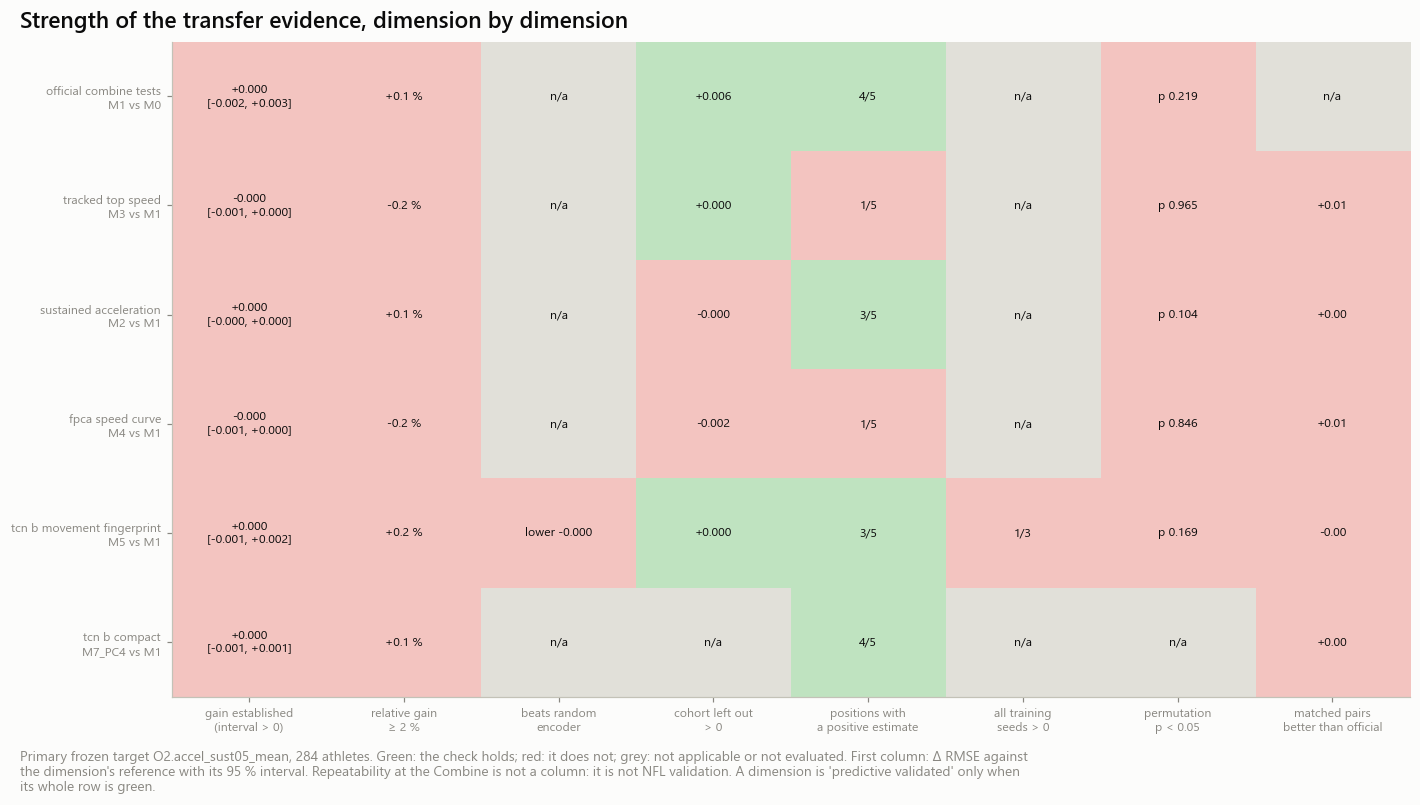

In [15]:
COMPACT = families.get('COMPACT') if families.get('COMPACT') in tc.compact_dims else None
evidence = save(tx.evidence_table(P, paired, sub_paired, loco_paired, seed_paired, perm, pair_sum, hetero, tc, COMPACT), tx.EVIDENCE)
coverage = {name: f'{N} athletes in the paired cohort of {audit["n_roster"]} Combine athletes ({audit["n_primary_cohort"]} in the 06A primary cohort)'
            for name, *_ in tx.DIMENSIONS}
registry = save(tx.readiness_registry(evidence, shortlist, coverage, tc, COMPACT), tx.READINESS)
case = tx.decision_case(evidence, paired, sub_paired, P, tc)

with pl.Config(tbl_rows=20, float_precision=4, fmt_str_lengths=60):
    display(Markdown(f'**Evidence, dimension by dimension** — `{P}`'))
    display(evidence.select('dimension', 'model', 'reference', 'n_athletes', 'delta_rmse', 'ci_lower', 'ci_upper', 'relative', 'established',
                            'vs_random_lower', 'loco_delta', 'positions_positive', 'positions_total', 'seeds_positive', 'seeds_total',
                            'perm_p_outcome', 'perm_p_linkage', 'matched_d_concordance', 'heterogeneity_p_position'))
with pl.Config(tbl_rows=20, fmt_str_lengths=400, tbl_width_chars=260):
    display(Markdown('**Scoring readiness registry**'))
    display(registry.select('name', 'status', 'status_reason', 'effect_size', 'confidence_interval'))
    display(registry.select('name', 'candidate_feature_source', 'physical_interpretation', 'reliability_evidence', 'stopwatch_redundancy'))
    display(registry.select('name', 'nfl_transfer_evidence', 'cohort_robustness', 'position_applicability', 'measurement_coverage'))
display(Markdown(f'### Decision-tree case {case[0]}\n{case[1]}'))
conditions = tx.scoring_conditions(registry, case[0], tc)
display(Markdown(conditions))
store.show(tf.plot_evidence(evidence, tc.min_relative_gain, tc.perm_alpha), 'AM06C_10_final_evidence_strength_summary', {'evidence': evidence},
           publication=True, source='transfer_evidence_summary', n=NTXT)

## 10. Gate 06C — scouting interpretation

Pass only if: every reported gain carries its uncertainty · position and exposure limits are documented (evaluated and saved) · matched prospects were scored on out-of-fold predictions · case studies are labelled illustrative · the readiness registry reflects the evidence (no validated status without a positive, established effect; only allowed status values).

In [16]:
GATE_C = replace(tr.GATE, name='transfer_gate_06c')
gate = save(tx.gate_06c(evidence, sub_paired, sens_paired, pair_sum, pairs, cases, registry), GATE_C)
GATE_STATUS = 'PASS' if gate['passed'].all() else 'FAIL'
with pl.Config(fmt_str_lengths=220):
    display(gate)

reading = tx.conclusions_06c(evidence, registry, case, pair_sum, P) + '\n\n' + conditions
if controls.save_tables:
    (store.tables_dir / 'transfer_robustness_conclusions.md').write_text(reading, encoding='utf-8')
    store.write_json('transfer_robustness_manifest', {
        'notebook': PROV['notebook'], 'status': 'executed', 'gate_06c': GATE_STATUS, 'seed': controls.seed, 'targets_version_hash': TARGETS_HASH,
        'folds_hash': FOLDS_HASH, 'primary_target': P, 'n_primary_target': int(N), 'decision_case': case[0], 'decision_sentence': case[1],
        'readiness': dict(registry.select('name', 'status').iter_rows()), 'ran': {'loco': RUN_LOCO, 'seeds': RUN_SEEDS, 'permutations': RUN_PERMUTATIONS,
                                                                                  'attribution': RUN_ATTRIBUTION},
        'n_matched_pairs': pairs.height, 'sensitivity_rules_evaluated': sorted(done), 'transfer_config': tc.params(),
        'validation': validation_report.to_dicts(), 'executed_at': utc_now()})
tr.assert_gate(gate, '06C')
display(Markdown(f'### Gate 06C: {GATE_STATUS}'))
display(Markdown(reading))

14:41:24 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:06C] transfer_gate_06c: 5 rows → warehouse/gold/advanced_movement/transfer/transfer_gate_06c.parquet


criterion,passed,detail
str,bool,str
"""gains_reported_with_uncertainty""",true,"""6 of 6 dimension(s) carry a paired interval"""
"""position_and_exposure_limits_documented""",true,"""5 position groups and 10 exposure rules evaluated and saved"""
"""matched_prospects_out_of_fold""",true,"""833 matched pairs scored on out-of-fold predictions"""
"""case_studies_illustrative""",true,"""case studies are chosen by stopwatch distance only and labelled illustrative"""
"""readiness_reflects_evidence""",true,"""6 dimension(s); statuses {'exploratory': 4, 'descriptive_ready': 2}"""


### Gate 06C: PASS

### What the tables show (primary target `O2.accel_sust05_mean`)

- **official_combine_tests** (M1 vs M0, 284 athletes): Δ RMSE +0.000 [-0.002, +0.003]; cohort left out +0.006; positions with a positive estimate 4/5; permutation p +0.219.
- **tracked_top_speed** (M3 vs M1, 284 athletes): Δ RMSE -0.000 [-0.001, +0.000]; cohort left out +0.000; positions with a positive estimate 1/5; permutation p +0.965.
- **sustained_acceleration** (M2 vs M1, 284 athletes): Δ RMSE +0.000 [-0.000, +0.000]; cohort left out -0.000; positions with a positive estimate 3/5; permutation p +0.104.
- **fpca_speed_curve** (M4 vs M1, 284 athletes): Δ RMSE -0.000 [-0.001, +0.000]; cohort left out -0.002; positions with a positive estimate 1/5; permutation p +0.846.
- **tcn_b_movement_fingerprint** (M5 vs M1, 284 athletes): Δ RMSE +0.000 [-0.001, +0.002]; cohort left out +0.000; positions with a positive estimate 3/5; permutation p +0.169.
- **tcn_b_compact** (M7_PC4 vs M1, 284 athletes): Δ RMSE +0.000 [-0.001, +0.001]; cohort left out n/a; positions with a positive estimate 4/5; permutation p n/a.

Matched prospects (833 pairs, 275 athletes, an athlete in up to 14 pairs):
- M0: concordance 0.521 [0.449, 0.594]; vs official +0.020 [-0.025, +0.067]
- M1: concordance 0.501 [0.430, 0.573]
- M2: concordance 0.505 [0.436, 0.577]; vs official +0.005 [-0.014, +0.025]
- M3: concordance 0.510 [0.443, 0.583]; vs official +0.010 [-0.010, +0.031]
- M4: concordance 0.510 [0.442, 0.580]; vs official +0.010 [-0.013, +0.035]
- M5: concordance 0.496 [0.425, 0.568]; vs official -0.005 [-0.035, +0.028]
- M5S: concordance 0.507 [0.437, 0.577]; vs official +0.006 [-0.021, +0.036]
- M6: concordance 0.499 [0.433, 0.569]; vs official -0.001 [-0.031, +0.031]
- M7_PC2: concordance 0.505 [0.435, 0.576]; vs official +0.005 [-0.012, +0.023]
- M7_PC4: concordance 0.505 [0.436, 0.574]; vs official +0.005 [-0.038, +0.050]
- MEAN: concordance 0.379 [0.310, 0.447]; vs official -0.121 [-0.220, -0.019]
- POS: concordance 0.313 [0.249, 0.380]; vs official -0.187 [-0.269, -0.105]

Scoring readiness: `official_combine_tests` → **exploratory**; `tracked_top_speed` → **descriptive_ready**; `sustained_acceleration` → **exploratory**; `fpca_speed_curve` → **descriptive_ready**; `tcn_b_movement_fingerprint` → **exploratory**; `tcn_b_compact` → **exploratory**.

Decision-tree case **E** — no method is shown to improve on official Combine testing for the frozen primary NFL target: report the negative finding, keep the Combine profiles as descriptions, build no Athletic Transfer Score.

Limits: the labels are observed NFL movement, shaped by role, scheme and usage as well as ability; draft cohorts differ in sensor generation and in NFL follow-up; intervals cover athlete sampling, not the refitting of the models; subgroup and matched-pair results are exploratory unless the pooled comparison is established.

### Conditions for the scoring milestone

A dimension may enter a PREDICTIVE score only when, on the frozen primary NFL target and the paired cohort:
1. its model lowers held-out RMSE against its reference with a 95 % athlete-bootstrap interval above 0;
2. the relative gain is at least 2 % of the reference error;
3. the gain stays positive with each draft cohort left out, and in at least three position groups;
4. the outcome-permutation check gives p < 0.05;
5. for the encoder: it beats the random encoder and the gain is positive for every training seed.
A dimension with a reliable Combine measurement and no established gain may enter a DESCRIPTIVE profile only, labelled as such.

- Meeting 1–5 in this run (`predictive_validated`): none
- Meeting 1 only (`predictive_candidate`, needs replication or the missing checks): none
- Decision-tree case: **E**

## 11. What a successful Milestone 06 distinguishes

| Distinction | Where it is made |
|---|---|
| repeatability from predictive value | Milestones 02–04 measured repeatability; only 06B / 06C measure prediction, and the readiness rule never counts the former as the latter |
| speed from acceleration | separate frozen targets (06B figure 7); SPEED2 as a control (M3, M5S) |
| official-test redundancy from incremental information | every comparison is against M1, on identical athletes |
| athlete ability from recorded opportunity | exposure and context rules (section 4); the label is observed movement, and the limits say so |
| model accuracy from actionable scouting benefit | practical margin, matched prospects, readiness registry |
| exploratory patterns from confirmed findings | one primary comparison; everything else labelled secondary or exploratory |

**Outputs** (`…/advanced_movement/transfer/`): `transfer_subgroup_performance`, `transfer_subgroup_comparisons`, `transfer_gain_heterogeneity`, `transfer_*_loco`, `transfer_*_sens`, `transfer_*_seeds`, `transfer_matched_pairs`, `transfer_matched_pair_predictions`, `transfer_matched_pair_summary`, `transfer_physical_mechanism`, `transfer_permutation`, `transfer_ci_stability`, `transfer_evidence_summary`, **`scoring_readiness_registry`**, `transfer_gate_06c`, `transfer_robustness_conclusions.md`, `transfer_robustness_manifest.json`, figures `AM06C_01`–`AM06C_10`.

**Stop here.** Fill `reports/COMBINE_TO_NFL_TRANSFER_VALIDATION.md` from the saved tables and send back the items listed in `notebooks/advanced_movement/README.md`. The scoring milestone is designed only after that review, and only along the decision-tree case this notebook returned.